
# Triagegeist — Baseline amélioré
## Aide à la décision pour le triage ESI (1–5) : features structurées + NLP + garde-fou de sécurité + audit d'équité

**Compétition :** Triagegeist — AI in Emergency Triage  |  **Hôte :** Laitinen-Fredriksson Foundation  |  **Auteur :** Nayrouz Weslati

---

### Problème clinique visé
Le triage ESI est subjectif, variable d'un évaluateur à l'autre et réalisé sous pression. Un **sous-triage** (patient ESI-1/2 classé ESI-4/5) est l'erreur la plus dangereuse. Ce notebook construit un **outil d'aide à la décision** (il ne remplace pas le clinicien) qui :
1. prédit le niveau ESI à partir des données d'admission et de la plainte principale ;
2. mesure et limite le **sous-triage critique** (métrique de sécurité + garde-fou à règles) ;
3. **audite l'équité** (sexe, langue, assurance, site, infirmier) et la variabilité inter-évaluateur ;
4. vérifie honnêtement la **robustesse** : le texte de la plainte semble quasi-déterministe de l'acuité dans ce jeu (section 5.3), donc un modèle **sans texte** est rapporté comme référence cliniquement plus réaliste.



## 1. Imports et configuration

**Réglages principaux** (cellule de configuration ci-dessous) :
- `QUICK_DEBUG = True` → sous-échantillonne train, réduit le nombre d'arbres et désactive les embeddings : permet de vérifier tout le notebook en quelques minutes avant un vrai run.
- `RUN_STRUCT_COMPARISON`, `RUN_MINILM`, `RUN_BCB` → désactivent les parties les plus longues (la comparaison structurée prend ~46 min).
- `FINAL_TEXT`, `FORCE_GROUPS`, `FORCE_STRATEGY` → forcent un choix manuel au lieu de la sélection automatique.
- `USE_TEXT_IN_FINAL` → `True` : le modèle soumis utilise le texte (meilleur QWK) ; `False` : modèle structuré seul.
- `RUN_GROUPED_CV`, `RUN_FAIRNESS` → activent la CV groupée par plainte et l'audit d'équité.


In [ ]:
import importlib.util, subprocess, sys

_REQ = {'lightgbm': 'lightgbm', 'xgboost': 'xgboost', 'catboost': 'catboost',
        'shap': 'shap', 'statsmodels': 'statsmodels', 'joblib': 'joblib'}
_missing = [pip for mod, pip in _REQ.items() if importlib.util.find_spec(mod) is None]
if _missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *_missing])
    print('Installé :', _missing)
else:
    print('Dépendances de base déjà présentes.')

Installé : ['catboost']


In [ ]:
import os, re, time, json, hashlib, warnings, importlib.util
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings('ignore')

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import (cohen_kappa_score, accuracy_score, f1_score, recall_score,
                             classification_report, confusion_matrix)
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostClassifier
import shap
import joblib

# ── Réglages généraux ────────────────────────────────────────────────────
SEED = 2025
N_FOLDS = 5
np.random.seed(SEED)

QUICK_DEBUG           = False   # True = vérification rapide de tout le notebook (résultats non exploitables)
RUN_STRUCT_COMPARISON = False    # False = saute les 5 modèles de l'étape 2 (~46 min), réutilise vos résultats précédents
RUN_MINILM            = True    # embeddings MiniLM (étape 3)
RUN_BCB               = True    # embeddings BioClinicalBERT (étape 3) — idéalement avec GPU
EMB_PCA_DIMS          = 64      # réduction PCA des embeddings (None = embeddings bruts)
FINAL_TEXT            = 'auto'  # 'auto' | 'tfidf' | 'minilm' | 'bcb'
FORCE_GROUPS          = None    # ex. ['missing', 'temporal'] pour forcer les groupes de features retenus
FORCE_STRATEGY        = None    # 'balanced' | 'oversample' | 'focal'
USE_TEXT_IN_FINAL     = True    # True = modèle soumis AVEC texte (meilleur QWK, mais texte quasi-déterministe, voir 5.3) ; False = structuré seul
RUN_GROUPED_CV        = True    # CV groupée par texte de plainte (test de robustesse, quelques minutes)
RUN_FAIRNESS          = True    # audit d'équité (section 8.2)

# ── Hyperparamètres LightGBM ─────────────────────────────────────────────
# subsample_freq=1 est indispensable : sans lui LightGBM ignore `subsample`.
_LGB_COMMON = dict(subsample=0.85, subsample_freq=1, reg_alpha=0.1, reg_lambda=0.1,
                   min_child_samples=30, n_jobs=-1, verbose=-1)
LGB_FAST  = dict(n_estimators=300, learning_rate=0.10, num_leaves=31, colsample_bytree=0.5,  **_LGB_COMMON)  # exploration
LGB_FINAL = dict(n_estimators=600, learning_rate=0.05, num_leaves=63, colsample_bytree=0.85, **_LGB_COMMON)  # modèle final
N_TREES_CMP, RF_TREES, SHAP_SAMPLE = 600, 500, 1500

if QUICK_DEBUG:
    LGB_FAST['n_estimators'], LGB_FINAL['n_estimators'] = 40, 60
    N_TREES_CMP, RF_TREES, SHAP_SAMPLE = 40, 40, 300
    RUN_MINILM = RUN_BCB = False

TARGET_NAMES = ['ESI-1', 'ESI-2', 'ESI-3', 'ESI-4', 'ESI-5']
ESI_COLORS = ['#d32f2f', '#f57c00', '#fbc02d', '#388e3c', '#1976d2']

# ── Environnement (Kaggle / Colab / local) ───────────────────────────────
# Colab possède parfois un dossier /kaggle/input vide : on détecte donc par variable d'environnement / module
if os.environ.get('KAGGLE_KERNEL_RUN_TYPE'):
    import glob
    _hits = glob.glob('/kaggle/input/**/train.csv', recursive=True)      # détecte le vrai dossier du jeu de données
    _root = (os.path.dirname(_hits[0]) + '/') if _hits else '/kaggle/input/triagegeist/'
    RUNTIME, DATA_PATH, ARTIFACT_DIR = 'kaggle', _root, '/kaggle/working/artifacts/'
elif importlib.util.find_spec('google.colab') is not None:
    RUNTIME = 'colab'
    from google.colab import drive
    drive.mount('/content/drive')
    DATA_PATH = '/content/drive/MyDrive/triagegeist/'
    ARTIFACT_DIR = DATA_PATH + 'artifacts/'      # sur Drive : survit à une déconnexion de Colab
else:
    RUNTIME, DATA_PATH, ARTIFACT_DIR = 'local', './data/', './artifacts/'
os.makedirs(ARTIFACT_DIR, exist_ok=True)

print(f'Environnement : {RUNTIME} | données : {DATA_PATH} | artefacts : {ARTIFACT_DIR}')
print(f'LightGBM {lgb.__version__} | XGBoost {xgb.__version__} | pandas {pd.__version__}')
print(f'QUICK_DEBUG = {QUICK_DEBUG}')

Mounted at /content/drive
Environnement : colab | données : /content/drive/MyDrive/triagegeist/ | artefacts : /content/drive/MyDrive/triagegeist/artifacts/
LightGBM 4.6.0 | XGBoost 3.4.1 | pandas 2.2.3
QUICK_DEBUG = False


## 2. Chargement des données

Les quatre fichiers sont joints sur `patient_id` plus loin (section 4), après l'EDA.

In [ ]:
train      = pd.read_csv(DATA_PATH + 'train.csv')
test       = pd.read_csv(DATA_PATH + 'test.csv')
cc         = pd.read_csv(DATA_PATH + 'chief_complaints.csv')
history    = pd.read_csv(DATA_PATH + 'patient_history.csv')
sample_sub = pd.read_csv(DATA_PATH + 'sample_submission.csv')

if QUICK_DEBUG:   # sous-échantillonnage de train uniquement (le test reste complet)
    train = train.sample(n=min(10000, len(train)), random_state=SEED).reset_index(drop=True)

assert 'triage_acuity' in train.columns and 'triage_acuity' not in test.columns

# Colonnes de comorbidités : préfixe hx_ (détection binaire en repli)
COMORB_COLS = [c for c in history.columns if c.startswith('hx_')]
if not COMORB_COLS:
    COMORB_COLS = [c for c in history.columns if c != 'patient_id'
                   and pd.api.types.is_numeric_dtype(history[c]) and history[c].dropna().isin([0, 1]).all()]

print(f'Train:            {train.shape[0]:,} rows x {train.shape[1]} cols')
print(f'Test:             {test.shape[0]:,} rows x {test.shape[1]} cols')
print(f'Chief complaints: {cc.shape[0]:,} rows x {cc.shape[1]} cols')
print(f'Patient history:  {history.shape[0]:,} rows x {history.shape[1]} cols  ({len(COMORB_COLS)} comorbidités)')
train.head(3)

Train:            80,000 rows x 40 cols
Test:             20,000 rows x 37 cols
Chief complaints: 100,000 rows x 3 cols
Patient history:  100,000 rows x 26 cols  (25 comorbidités)


,patient_id,site_id,triage_nurse_id,arrival_mode,arrival_hour,arrival_day,arrival_month,arrival_season,shift,age,...,gcs_total,pain_score,weight_kg,height_cm,bmi,shock_index,news2_score,disposition,ed_los_hours,triage_acuity
0,TG-UXRGA9UCO,SITE-TMP-01,NURSE-0033,walk-in,6,Monday,5,spring,morning,43,...,14,7,52.3,165.4,19.1,0.725,8,discharged,7.35,2
1,TG-B19DBBS2G,SITE-HEL-01,NURSE-0001,walk-in,6,Thursday,4,spring,morning,72,...,15,-1,73.3,164.4,27.1,0.739,1,discharged,0.70,5
2,TG-GZ97W7M6V,SITE-HEL-02,NURSE-0005,walk-in,8,Saturday,4,spring,morning,82,...,15,3,77.1,183.7,22.8,0.798,2,discharged,0.63,5


## 3. Analyse exploratoire (Étape 1 du pipeline)

### 3.1 EDA du baseline

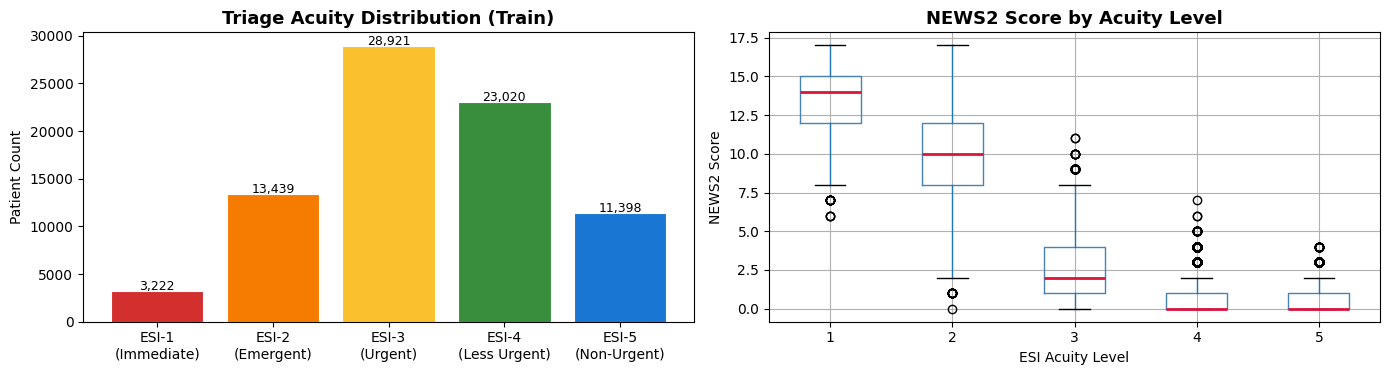

In [ ]:
# Target distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

acu_counts = train['triage_acuity'].value_counts().sort_index()
acu_labels = ['ESI-1\n(Immediate)', 'ESI-2\n(Emergent)', 'ESI-3\n(Urgent)',
              'ESI-4\n(Less Urgent)', 'ESI-5\n(Non-Urgent)']
colors = ['#d32f2f','#f57c00','#fbc02d','#388e3c','#1976d2']

axes[0].bar(acu_labels, acu_counts.values, color=colors, edgecolor='white', linewidth=0.8)
axes[0].set_title('Triage Acuity Distribution (Train)', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Patient Count')
for i, v in enumerate(acu_counts.values):
    axes[0].text(i, v + 100, f'{v:,}', ha='center', fontsize=9)

# NEWS2 score by acuity
train.boxplot(column='news2_score', by='triage_acuity', ax=axes[1],
              boxprops=dict(color='steelblue'),
              medianprops=dict(color='crimson', linewidth=2))
axes[1].set_title('NEWS2 Score by Acuity Level', fontsize=13, fontweight='bold')
axes[1].set_xlabel('ESI Acuity Level')
axes[1].set_ylabel('NEWS2 Score')
plt.suptitle('')
plt.tight_layout()
plt.show()

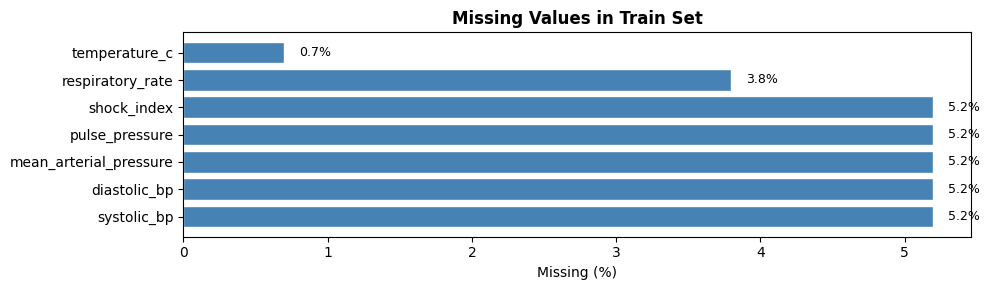


Note: pain_score = -1 means not recorded (not a true NaN).
pain_score -1 count: 11,156


In [ ]:
# Missing value analysis
miss = train.isnull().sum()
miss = miss[miss > 0].sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 3))
miss_pct = (miss / len(train) * 100).round(1)
ax.barh(miss_pct.index, miss_pct.values, color='steelblue', edgecolor='white')
ax.set_xlabel('Missing (%)')
ax.set_title('Missing Values in Train Set', fontsize=12, fontweight='bold')
for i, v in enumerate(miss_pct.values):
    ax.text(v + 0.1, i, f'{v}%', va='center', fontsize=9)
plt.tight_layout()
plt.show()

print('\nNote: pain_score = -1 means not recorded (not a true NaN).')
print(f'pain_score -1 count: {(train["pain_score"] == -1).sum():,}')

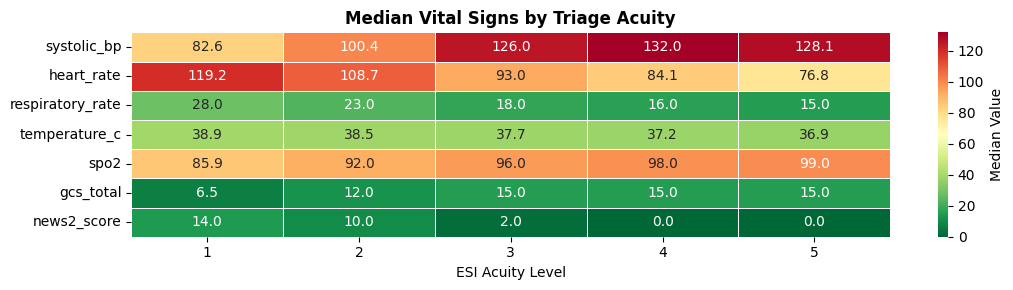

In [ ]:
# Vital signs by acuity — heatmap of medians
vital_cols = ['systolic_bp','heart_rate','respiratory_rate','temperature_c','spo2','gcs_total','news2_score']
medians = train.groupby('triage_acuity')[vital_cols].median()

fig, ax = plt.subplots(figsize=(11, 3))
sns.heatmap(medians.T, annot=True, fmt='.1f', cmap='RdYlGn_r',
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Median Value'})
ax.set_xlabel('ESI Acuity Level')
ax.set_title('Median Vital Signs by Triage Acuity', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

## Sommaire de l'EDA approfondie:

A. Qualité et cohérence des données   
B. Distributions univariées approfondies                       
C. Relations entre variables (corrélations, multicolinéarité, tests statistiques)                   
D. Contexte et équité (site, infirmier, langue, assurance, sexe)   
E. Effet de la charge / du poste (crowding)                            
F. Antécédents médicaux (comorbidités)                       
G. Texte des plaintes (chief complaints)                          
H. Cohérence clinique (sanity checks)

### 3.2 EDA approfondie (compléments A à H)

In [ ]:
# Bibliothèques additionnelles utilisées dans ce complément
# !pip install -q statsmodels
from scipy.stats import ks_2samp, spearmanr, kruskal, chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant
from collections import Counter
import re

ESI_COLORS = ['#d32f2f', '#f57c00', '#fbc02d', '#388e3c', '#1976d2']

#### A. Qualité et cohérence des données

In [ ]:
# A1. Valeurs hors plage physiologique plausible
plausible_ranges = {
    'heart_rate':       (20, 250),
    'systolic_bp':      (40, 260),
    'diastolic_bp':     (20, 150),
    'respiratory_rate': (4, 60),
    'temperature_c':    (30, 43),
    'spo2':             (50, 100),
    'gcs_total':        (3, 15),
    'news2_score':      (0, 20),
}

print('Valeurs hors plage physiologique plausible :')
for col, (lo, hi) in plausible_ranges.items():
    if col in train.columns:
        n_valid = train[col].notna().sum()
        n_out = ((train[col] < lo) | (train[col] > hi)).sum()
        pct = (n_out / n_valid * 100) if n_valid else 0
        flag = '  <-- à vérifier' if n_out > 0 else ''
        print(f'  {col:18s}: {n_out:5d} valeurs hors [{lo}, {hi}]  ({pct:.2f}%){flag}')
    else:
        print(f'  {col:18s}: colonne absente — adapter le nom si besoin')

Valeurs hors plage physiologique plausible :
  heart_rate        :     0 valeurs hors [20, 250]  (0.00%)
  systolic_bp       :     0 valeurs hors [40, 260]  (0.00%)
  diastolic_bp      :     0 valeurs hors [20, 150]  (0.00%)
  respiratory_rate  :     0 valeurs hors [4, 60]  (0.00%)
  temperature_c     :     0 valeurs hors [30, 43]  (0.00%)
  spo2              :     0 valeurs hors [50, 100]  (0.00%)
  gcs_total         :     0 valeurs hors [3, 15]  (0.00%)
  news2_score       :     0 valeurs hors [0, 20]  (0.00%)


In [ ]:
# A2. Comparaison des distributions train vs test (test de Kolmogorov-Smirnov)
numeric_cols_check = ['heart_rate', 'systolic_bp', 'diastolic_bp', 'respiratory_rate',
                       'temperature_c', 'spo2', 'gcs_total', 'news2_score',
                       'pain_score', 'age']
numeric_cols_check = [c for c in numeric_cols_check if c in train.columns and c in test.columns]

ks_results = []
for col in numeric_cols_check:
    stat, p = ks_2samp(train[col].dropna(), test[col].dropna())
    ks_results.append({'feature': col, 'ks_stat': stat, 'p_value': p,
                        'drift_suspect': p < 0.01})

ks_df = pd.DataFrame(ks_results).sort_values('ks_stat', ascending=False)
print('Test KS train vs test (drift_suspect=True -> distributions significativement différentes) :')
ks_df

Test KS train vs test (drift_suspect=True -> distributions significativement différentes) :


,feature,ks_stat,p_value,drift_suspect
2,diastolic_bp,0.009966,0.096634,False
9,age,0.008888,0.158676,False
5,spo2,0.006937,0.422590,False
8,pain_score,0.006200,0.567808,False
3,respiratory_rate,0.006001,0.634065,False
1,systolic_bp,0.005585,0.727195,False
4,temperature_c,0.003717,0.979922,False
0,heart_rate,0.003513,0.988732,False
7,news2_score,0.003225,0.996128,False
6,gcs_total,0.003075,0.998050,False


In [ ]:
# A3. Doublons et chevauchement train/test
print(f'Doublons patient_id (train)          : {train["patient_id"].duplicated().sum()}')
print(f'Doublons patient_id (test)           : {test["patient_id"].duplicated().sum()}')
print(f'Lignes totalement dupliquées (train) : {train.duplicated().sum()}')

overlap = set(train['patient_id']).intersection(set(test['patient_id']))
print(f'Patients présents à la fois dans train et test : {len(overlap)}')

Doublons patient_id (train)          : 0
Doublons patient_id (test)           : 0
Lignes totalement dupliquées (train) : 0
Patients présents à la fois dans train et test : 0


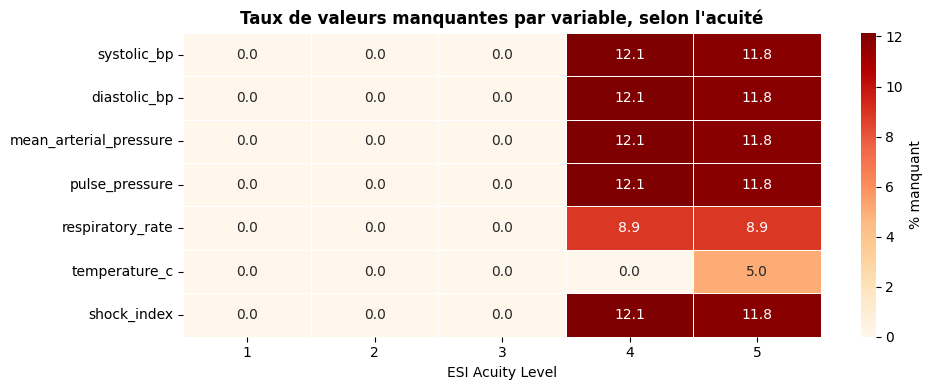

In [ ]:
# A4. Carte de valeurs manquantes croisée avec l'acuité
miss_cols = train.columns[train.isnull().any()].tolist()

if miss_cols:
    miss_by_acuity = train.groupby('triage_acuity')[miss_cols].apply(lambda x: x.isnull().mean() * 100)
    fig, ax = plt.subplots(figsize=(10, 4))
    sns.heatmap(miss_by_acuity.T, annot=True, fmt='.1f', cmap='OrRd',
                linewidths=0.5, ax=ax, cbar_kws={'label': '% manquant'})
    ax.set_xlabel('ESI Acuity Level')
    ax.set_title("Taux de valeurs manquantes par variable, selon l'acuité",
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.show()
else:
    print('Aucune colonne avec valeurs manquantes détectée.')

#### B. Distributions univariées approfondies

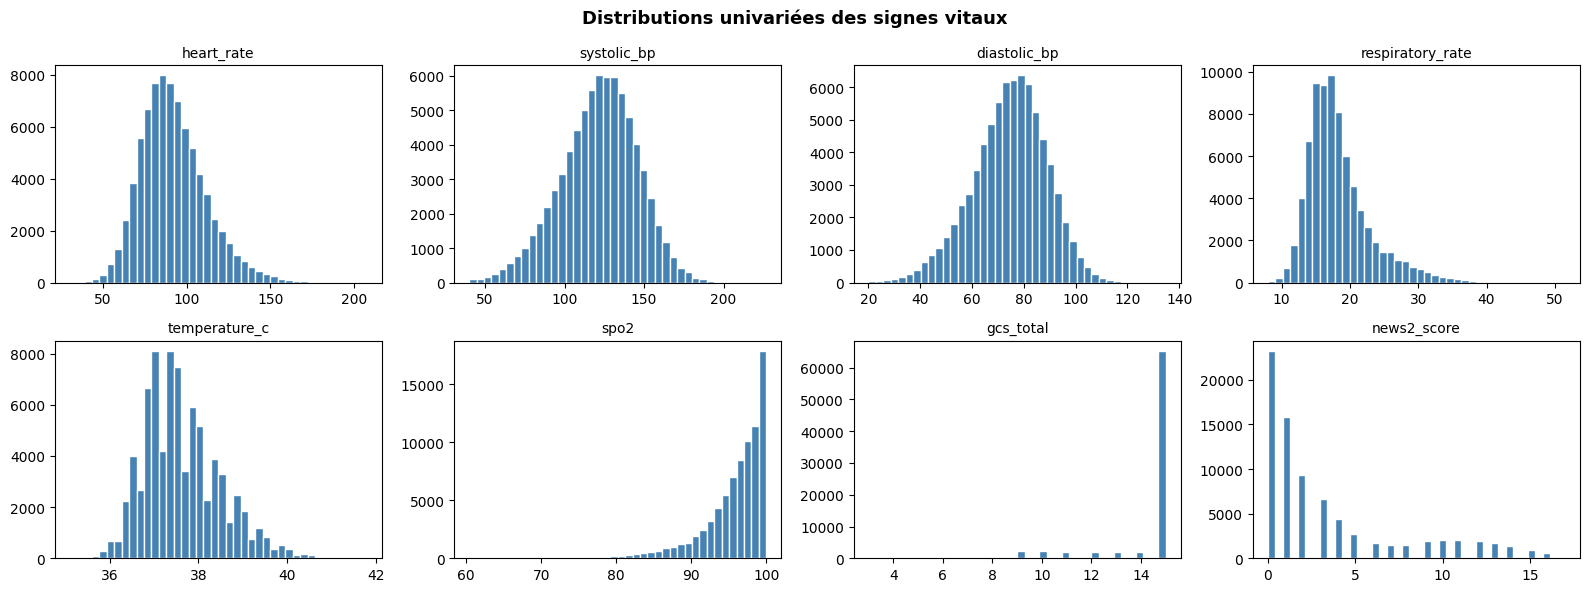

In [ ]:
# B1. Histogrammes des signes vitaux
vital_cols_hist = ['heart_rate', 'systolic_bp', 'diastolic_bp', 'respiratory_rate',
                    'temperature_c', 'spo2', 'gcs_total', 'news2_score']
vital_cols_hist = [c for c in vital_cols_hist if c in train.columns]

n_cols = 4
n_rows = int(np.ceil(len(vital_cols_hist) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 3 * n_rows))
axes = np.array(axes).flatten()

for i, col in enumerate(vital_cols_hist):
    axes[i].hist(train[col].dropna(), bins=40, color='steelblue', edgecolor='white')
    axes[i].set_title(col, fontsize=10)
for j in range(len(vital_cols_hist), len(axes)):
    axes[j].axis('off')

plt.suptitle('Distributions univariées des signes vitaux', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

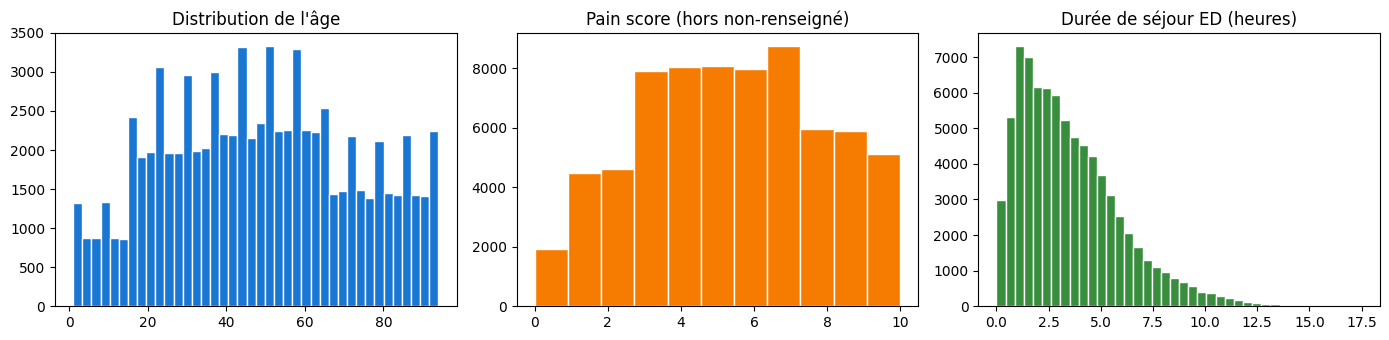

In [ ]:
# B2. Âge, pain_score (hors non-renseigné) et durée de séjour
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))

axes[0].hist(train['age'].dropna(), bins=40, color='#1976d2', edgecolor='white')
axes[0].set_title("Distribution de l'âge")

pain_valid = train.loc[train['pain_score'] != -1, 'pain_score']
axes[1].hist(pain_valid.dropna(), bins=11, color='#f57c00', edgecolor='white')
axes[1].set_title('Pain score (hors non-renseigné)')

if 'ed_los_hours' in train.columns:
    axes[2].hist(train['ed_los_hours'].dropna(), bins=40, color='#388e3c', edgecolor='white')
    axes[2].set_title('Durée de séjour ED (heures)')
else:
    axes[2].axis('off')

plt.tight_layout()
plt.show()

#### C. Relations entre variables

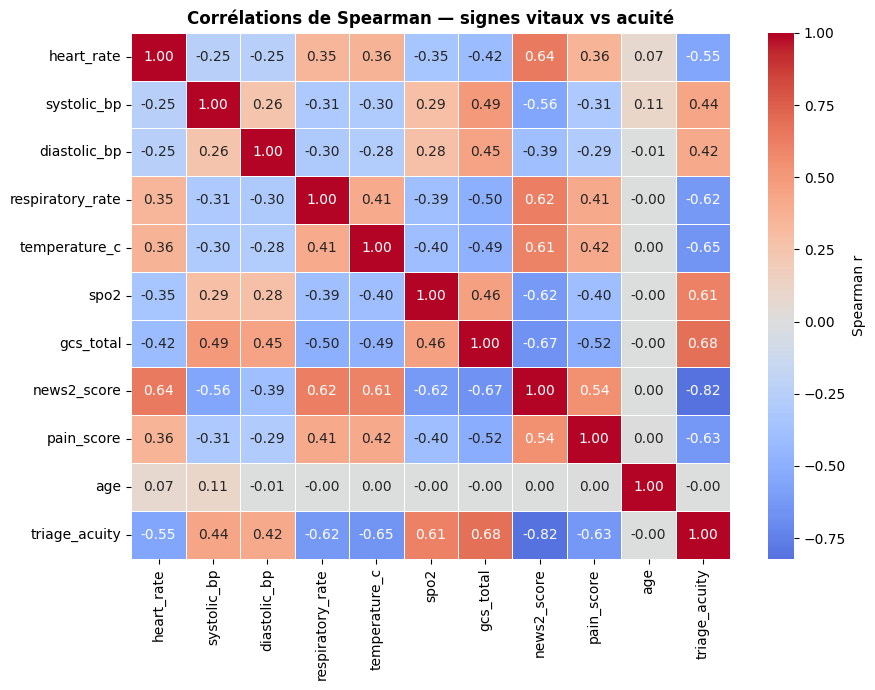

Corrélation avec triage_acuity, triée par force (valeur absolue) :
news2_score        -0.821505
gcs_total           0.683588
temperature_c      -0.646624
pain_score         -0.634663
respiratory_rate   -0.623952
spo2                0.614675
heart_rate         -0.551538
systolic_bp         0.442860
diastolic_bp        0.418563
age                -0.003688
Name: triage_acuity, dtype: float64


In [ ]:
# C1. Corrélations de Spearman (cible ordinale -> Spearman plutôt que Pearson)
corr_cols = ['heart_rate', 'systolic_bp', 'diastolic_bp', 'respiratory_rate',
             'temperature_c', 'spo2', 'gcs_total', 'news2_score', 'pain_score',
             'age', 'triage_acuity']
corr_cols = [c for c in corr_cols if c in train.columns]

corr_matrix = train[corr_cols].corr(method='spearman')

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Spearman r'})
ax.set_title('Corrélations de Spearman — signes vitaux vs acuité', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print('Corrélation avec triage_acuity, triée par force (valeur absolue) :')
print(corr_matrix['triage_acuity'].drop('triage_acuity').sort_values(key=abs, ascending=False))

In [ ]:

# C2. Multicolinéarité : pulse_pressure et mean_arterial_pressure sont-elles des combinaisons exactes de SBP/DBP ?
base_bp = train[['systolic_bp', 'diastolic_bp']].dropna()
A = np.c_[base_bp.values, np.ones(len(base_bp))]
print('R² de la régression linéaire sur (systolic_bp, diastolic_bp) :')
for target in [c for c in ['pulse_pressure', 'mean_arterial_pressure'] if c in train.columns]:
    t = train.loc[base_bp.index, target].values
    coef = np.linalg.lstsq(A, t, rcond=None)[0]
    r2 = 1 - ((t - A @ coef) ** 2).sum() / ((t - t.mean()) ** 2).sum()
    print(f'  {target:24s}: R² = {r2:.6f}  -> {"combinaison exacte : à retirer des modèles linéaires" if r2 > 0.9999 else "non exacte"}')

# VIF sur les variables restantes (sans les combinaisons exactes, qui rendent la matrice singulière)
vif_cols = [c for c in ['systolic_bp', 'diastolic_bp', 'shock_index', 'heart_rate', 'respiratory_rate'] if c in train.columns]
vif_data_const = add_constant(train[vif_cols].dropna())
vif_results = pd.DataFrame({
    'feature': vif_data_const.columns,
    'VIF': [variance_inflation_factor(vif_data_const.values, i) for i in range(vif_data_const.shape[1])]
})
vif_results = vif_results[vif_results['feature'] != 'const'].sort_values('VIF', ascending=False)
print('\nVIF par variable (VIF > 10 indique une forte multicolinéarité) :')
vif_results


R² de la régression linéaire sur (systolic_bp, diastolic_bp) :
  pulse_pressure          : R² = 1.000000  -> combinaison exacte : à retirer des modèles linéaires
  mean_arterial_pressure  : R² = 0.999996  -> combinaison exacte : à retirer des modèles linéaires

VIF par variable (VIF > 10 indique une forte multicolinéarité) :


,feature,VIF
3,shock_index,10.272325
1,systolic_bp,4.789202
4,heart_rate,4.468747
5,respiratory_rate,1.395714
2,diastolic_bp,1.222722


In [ ]:
# C3. Tests statistiques formels (continue ~ acuité, catégorielle ~ acuité)
print('Test de Kruskal-Wallis (variable continue selon triage_acuity) :')
continuous_test_cols = [c for c in ['heart_rate', 'systolic_bp', 'diastolic_bp',
                                     'respiratory_rate', 'temperature_c', 'spo2',
                                     'gcs_total', 'news2_score', 'age']
                         if c in train.columns]
for col in continuous_test_cols:
    groups = [g[col].dropna().values for _, g in train.groupby('triage_acuity')]
    stat, p = kruskal(*groups)
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
    print(f'  {col:18s}: H={stat:8.1f}  p={p:.2e}  {sig}')

print('\nTest du Chi² (variable catégorielle selon triage_acuity) :')
categorical_test_cols = [c for c in ['sex', 'language', 'insurance_type', 'arrival_mode',
                                      'arrival_day', 'arrival_season', 'shift',
                                      'transport_origin', 'mental_status_triage',
                                      'chief_complaint_system', 'site_id']
                          if c in train.columns]
for col in categorical_test_cols:
    contingency = pd.crosstab(train[col], train['triage_acuity'])
    chi2, p, dof, _ = chi2_contingency(contingency)
    sig = '***' if p < 0.001 else ('**' if p < 0.01 else ('*' if p < 0.05 else ''))
    print(f'  {col:22s}: chi2={chi2:8.1f}  dof={dof:3d}  p={p:.2e}  {sig}')

Test de Kruskal-Wallis (variable continue selon triage_acuity) :
  heart_rate        : H= 24712.0  p=0.00e+00  ***
  systolic_bp       : H= 21821.8  p=0.00e+00  ***
  diastolic_bp      : H= 18602.1  p=0.00e+00  ***
  respiratory_rate  : H= 30994.7  p=0.00e+00  ***
  temperature_c     : H= 33602.7  p=0.00e+00  ***
  spo2              : H= 30685.9  p=0.00e+00  ***
  gcs_total         : H= 69286.0  p=0.00e+00  ***
  news2_score       : H= 56565.0  p=0.00e+00  ***
  age               : H=     2.3  p=6.80e-01  

Test du Chi² (variable catégorielle selon triage_acuity) :
  sex                   : chi2=     1.7  dof=  8  p=9.89e-01  
  language              : chi2=    28.1  dof= 28  p=4.60e-01  
  insurance_type        : chi2=    15.6  dof= 16  p=4.80e-01  
  arrival_mode          : chi2=    16.0  dof= 20  p=7.15e-01  
  arrival_day           : chi2=    20.8  dof= 24  p=6.53e-01  
  arrival_season        : chi2=     8.8  dof= 12  p=7.17e-01  
  shift                 : chi2=    12.2  dof= 12  

#### D. Contexte et équité (site, infirmier, langue, assurance, sexe)

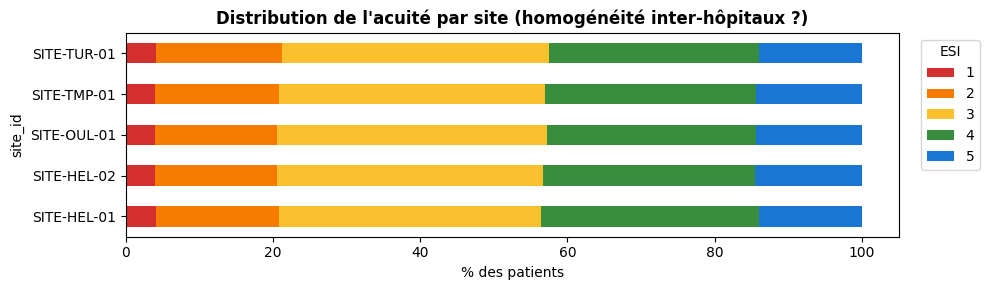

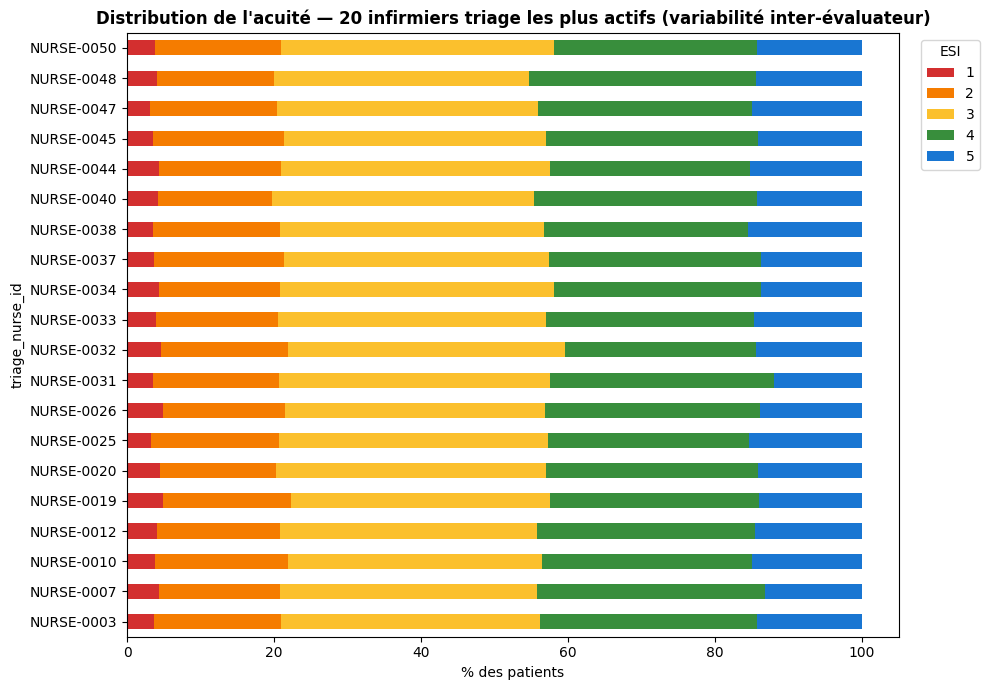

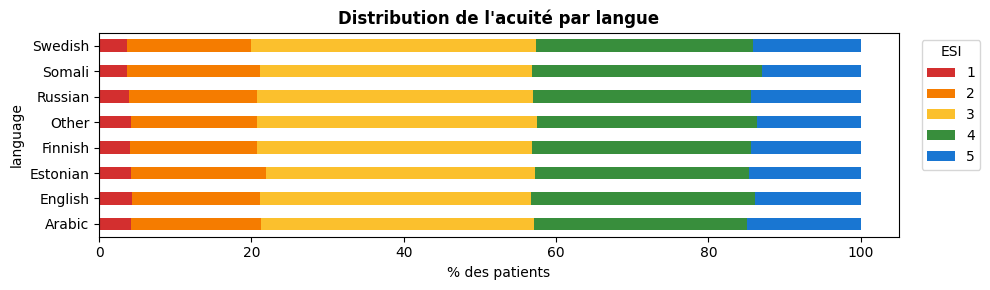

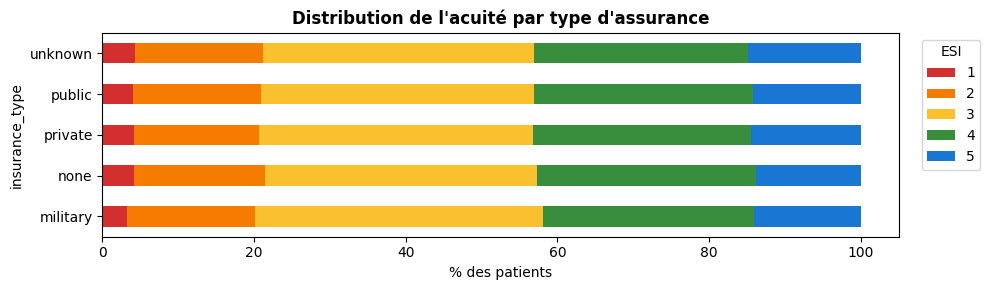

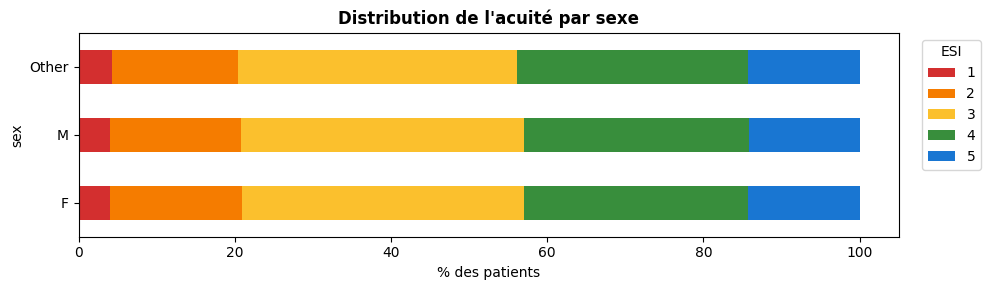

In [ ]:
def acuity_distribution_by(df, group_col, top_n=None, title=None):
    """Barres empilées (%) de l'acuité selon une variable de groupe.
    top_n limite aux catégories les plus fréquentes (utile pour les variables
    à forte cardinalité comme triage_nurse_id)."""
    if group_col not in df.columns:
        print(f'Colonne {group_col} absente — bloc ignoré.')
        return

    ct = pd.crosstab(df[group_col], df['triage_acuity'], normalize='index') * 100
    if top_n:
        top_cats = df[group_col].value_counts().head(top_n).index
        ct = ct.loc[ct.index.isin(top_cats)]

    fig, ax = plt.subplots(figsize=(10, max(3, 0.35 * len(ct))))
    ct.plot(kind='barh', stacked=True, ax=ax, color=ESI_COLORS)
    ax.set_xlabel('% des patients')
    ax.set_title(title or f"Distribution de l'acuité par {group_col}",
                 fontsize=12, fontweight='bold')
    ax.legend(title='ESI', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()

acuity_distribution_by(train, 'site_id',
    title="Distribution de l'acuité par site (homogénéité inter-hôpitaux ?)")
acuity_distribution_by(train, 'triage_nurse_id', top_n=20,
    title="Distribution de l'acuité — 20 infirmiers triage les plus actifs (variabilité inter-évaluateur)")
acuity_distribution_by(train, 'language',
    title="Distribution de l'acuité par langue")
acuity_distribution_by(train, 'insurance_type',
    title="Distribution de l'acuité par type d'assurance")
acuity_distribution_by(train, 'sex',
    title="Distribution de l'acuité par sexe")

#### E. Effet de la charge et du poste (crowding)

`arrival_hour` existe dans vos données : le crowding est calculé heure par heure dans la section 4.

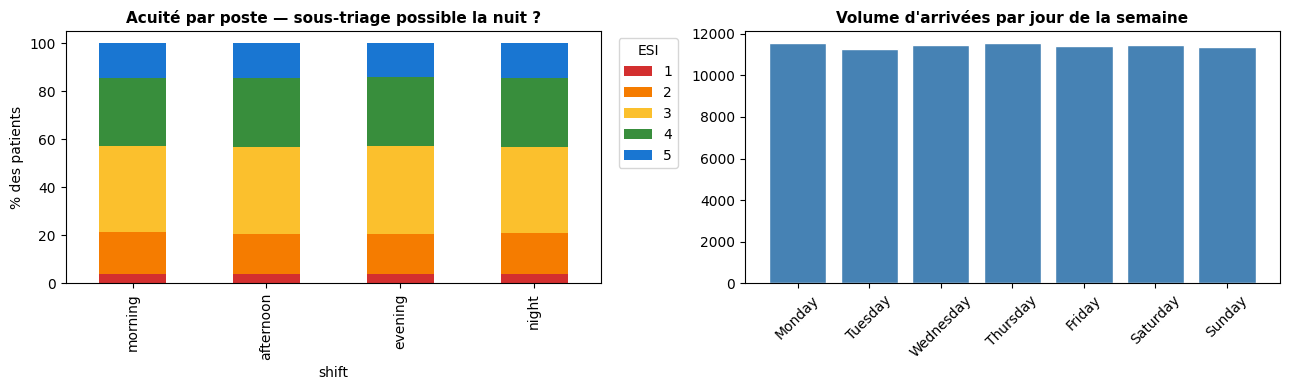

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

_shifts = list(train['shift'].unique())
_pref = ['morning', 'day', 'afternoon', 'evening', 'night']        # modalités réelles : morning, ... (voir train.head())
shift_order = [s for s in _pref if s in _shifts] + sorted(set(_shifts) - set(_pref))

ct_shift = pd.crosstab(train['shift'], train['triage_acuity'], normalize='index') * 100
ct_shift = ct_shift.reindex(shift_order)
ct_shift.plot(kind='bar', stacked=True, ax=axes[0], color=ESI_COLORS)
axes[0].set_title('Acuité par poste — sous-triage possible la nuit ?', fontsize=11, fontweight='bold')
axes[0].set_ylabel('% des patients')
axes[0].legend(title='ESI', bbox_to_anchor=(1.02, 1), loc='upper left')

day_order_full = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_order = [d for d in day_order_full if d in train['arrival_day'].unique()]
counts_day = train['arrival_day'].value_counts().reindex(day_order)
axes[1].bar(counts_day.index, counts_day.values, color='steelblue', edgecolor='white')
axes[1].set_title("Volume d'arrivées par jour de la semaine", fontsize=11, fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

#### F. Antécédents médicaux (comorbidités)

25 comorbidités : ['hx_hypertension', 'hx_diabetes_type2', 'hx_diabetes_type1', 'hx_asthma', 'hx_copd', 'hx_heart_failure', 'hx_atrial_fibrillation', 'hx_ckd', 'hx_liver_disease', 'hx_malignancy', 'hx_obesity', 'hx_depression', 'hx_anxiety', 'hx_dementia', 'hx_epilepsy', 'hx_hypothyroidism', 'hx_hyperthyroidism', 'hx_hiv', 'hx_coagulopathy', 'hx_immunosuppressed', 'hx_pregnant', 'hx_substance_use_disorder', 'hx_coronary_artery_disease', 'hx_stroke_prior', 'hx_peripheral_vascular_disease']


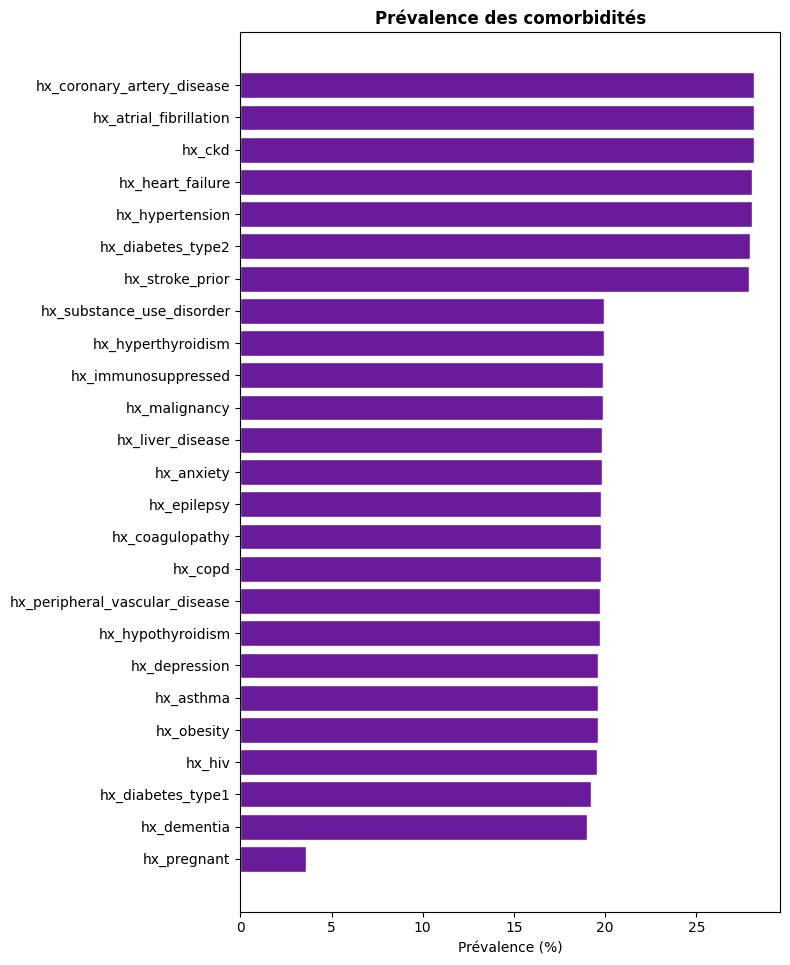

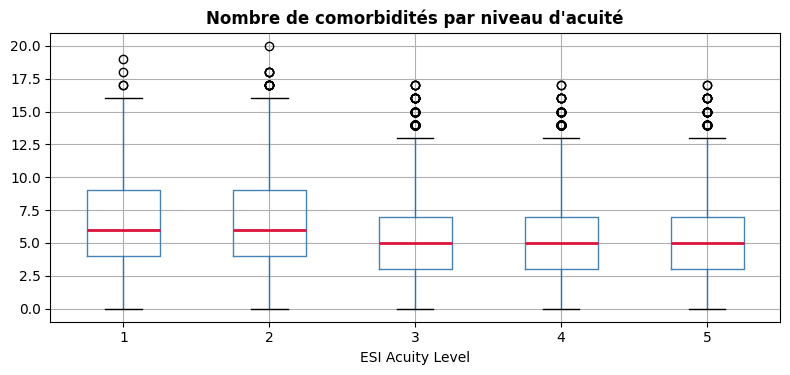


Corrélation de Spearman (flag comorbidité vs acuité), top 8 :
hx_hyperthyroidism    -0.0521
hx_liver_disease      -0.0511
hx_coagulopathy       -0.0507
hx_immunosuppressed   -0.0498
hx_anxiety            -0.0498
hx_asthma             -0.0487
hx_hiv                -0.0484
hx_diabetes_type1     -0.0479
dtype: float64


In [ ]:
# F. Comorbidités : prévalence, nombre par patient et lien avec l'acuité
# (correction : on n'ajoute plus de colonne à `history`, ce qui créait un doublon comorbidity_count_x/_y plus loin)
print(f'{len(COMORB_COLS)} comorbidités : {COMORB_COLS}')

if COMORB_COLS:
    prevalence = (history[COMORB_COLS].mean() * 100).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 0.35 * len(prevalence) + 1))
    ax.barh(prevalence.index[::-1], prevalence.values[::-1], color='#6a1b9a', edgecolor='white')
    ax.set_xlabel('Prévalence (%)')
    ax.set_title('Prévalence des comorbidités', fontsize=12, fontweight='bold')
    plt.tight_layout(); plt.show()

    hist_cnt = history[['patient_id']].copy()
    hist_cnt['comorbidity_count'] = history[COMORB_COLS].sum(axis=1)
    merged_hist = train[['patient_id', 'triage_acuity']].merge(hist_cnt, on='patient_id', how='left')

    fig, ax = plt.subplots(figsize=(8, 4))
    merged_hist.boxplot(column='comorbidity_count', by='triage_acuity', ax=ax,
                        boxprops=dict(color='steelblue'), medianprops=dict(color='crimson', linewidth=2))
    ax.set_title("Nombre de comorbidités par niveau d'acuité", fontsize=12, fontweight='bold')
    ax.set_xlabel('ESI Acuity Level'); plt.suptitle('')
    plt.tight_layout(); plt.show()

    # Les comorbidités portent-elles un signal ? (Spearman flag ~ acuité)
    m = train[['patient_id', 'triage_acuity']].merge(history[['patient_id'] + COMORB_COLS], on='patient_id', how='left')
    corr_hx = m[COMORB_COLS].corrwith(m['triage_acuity'], method='spearman').sort_values(key=abs, ascending=False)
    print('\nCorrélation de Spearman (flag comorbidité vs acuité), top 8 :')
    print(corr_hx.head(8).round(4))

#### G. Texte des plaintes (chief complaints)

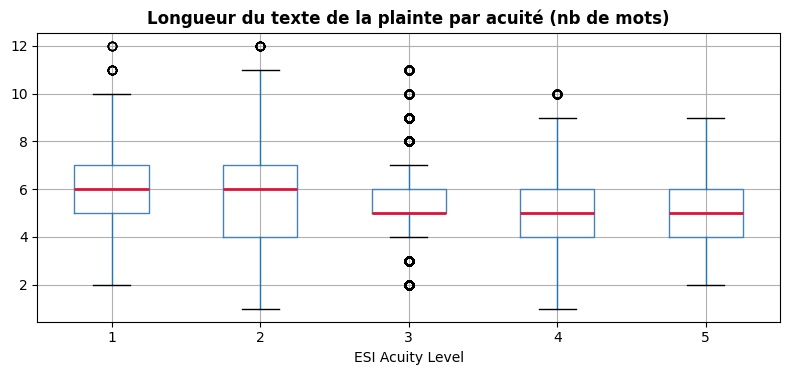

In [ ]:
cc_train = train[['patient_id', 'triage_acuity']].merge(
    cc[['patient_id', 'chief_complaint_raw']], on='patient_id', how='left')
cc_train['chief_complaint_raw'] = cc_train['chief_complaint_raw'].fillna('unknown')
cc_train['cc_length'] = cc_train['chief_complaint_raw'].str.split().apply(len)

fig, ax = plt.subplots(figsize=(8, 4))
cc_train.boxplot(column='cc_length', by='triage_acuity', ax=ax,
                  boxprops=dict(color='steelblue'),
                  medianprops=dict(color='crimson', linewidth=2))
ax.set_title('Longueur du texte de la plainte par acuité (nb de mots)', fontsize=12, fontweight='bold')
ax.set_xlabel('ESI Acuity Level')
plt.suptitle('')
plt.tight_layout()
plt.show()

In [ ]:
# Top mots par niveau d'acuité (filtrage simple de stopwords)
stopwords_simple = {'the', 'a', 'an', 'of', 'with', 'to', 'and', 'in', 'on',
                     'for', 'at', 'no', 'not', 'is', 'this'}

print("Top 10 mots par niveau d'acuité :")
for acuity in sorted(cc_train['triage_acuity'].unique()):
    texts = cc_train.loc[cc_train['triage_acuity'] == acuity, 'chief_complaint_raw']
    words = re.findall(r'\b[a-z]+\b', ' '.join(texts).lower())
    words = [w for w in words if w not in stopwords_simple and len(w) > 2]
    top10 = Counter(words).most_common(10)
    print(f'  ESI-{acuity}: {", ".join(w for w, _ in top10)}')

Top 10 mots par niveau d'acuité :
  ESI-1: severe, worsening, acute, shock, known, patient, fever, associated, nausea, syndrome
  ESI-2: acute, severe, worsening, significant, vomiting, fever, diaphoresis, suspected, since, yesterday
  ESI-3: worsening, moderate, fever, onset, vomiting, patient, pain, constant, movement, known
  ESI-4: mild, worsening, known, fever, days, nausea, vomiting, pain, minor, associated
  ESI-5: mild, worsening, advice, question, query, review, request, nausea, removal, rigors


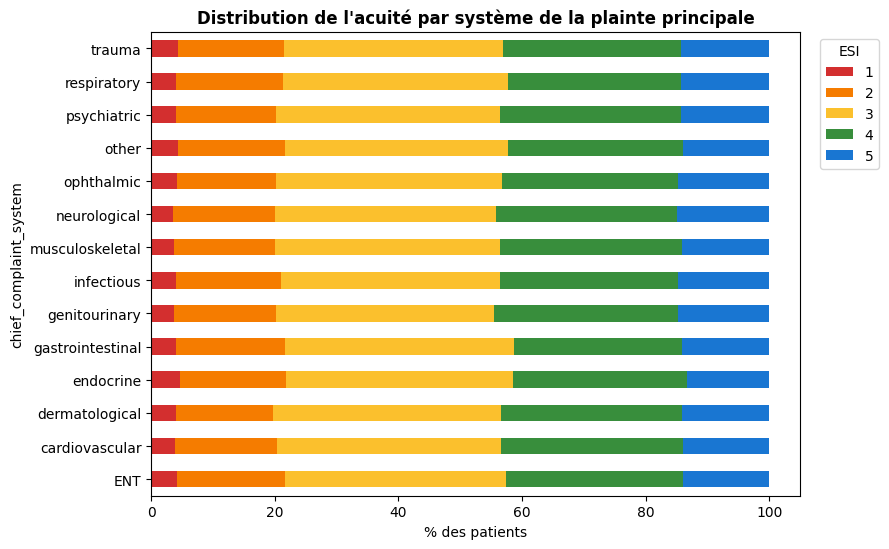

In [ ]:
# Système de la plainte principale (cardio, respiratoire, neuro...) vs acuité
if 'chief_complaint_system' in train.columns:
    ct_sys = pd.crosstab(train['chief_complaint_system'], train['triage_acuity'],
                          normalize='index') * 100
    fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(ct_sys))))
    ct_sys.plot(kind='barh', stacked=True, ax=ax, color=ESI_COLORS)
    ax.set_xlabel('% des patients')
    ax.set_title("Distribution de l'acuité par système de la plainte principale",
                 fontsize=12, fontweight='bold')
    ax.legend(title='ESI', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Colonne 'chief_complaint_system' absente — bloc ignoré.")

#### H. Cohérence clinique (sanity checks)

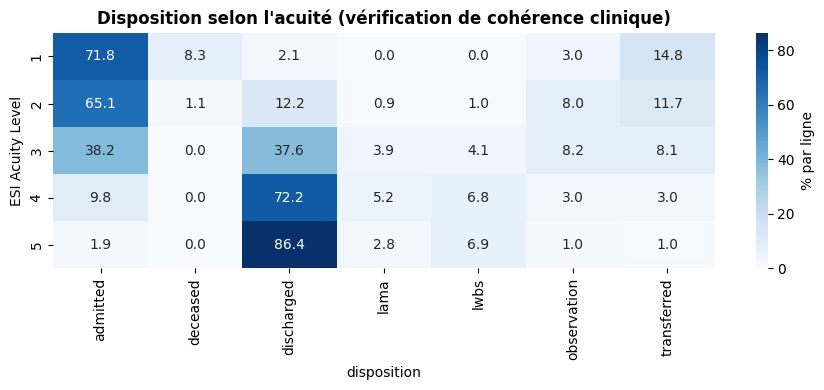

In [ ]:
# H1. Disposition vs acuité — un ESI-1 sorti directement serait suspect
if 'disposition' in train.columns:
    ct_disp = pd.crosstab(train['triage_acuity'], train['disposition'], normalize='index') * 100
    fig, ax = plt.subplots(figsize=(9, 4))
    sns.heatmap(ct_disp, annot=True, fmt='.1f', cmap='Blues', ax=ax,
                cbar_kws={'label': '% par ligne'})
    ax.set_title("Disposition selon l'acuité (vérification de cohérence clinique)",
                 fontsize=12, fontweight='bold')
    ax.set_ylabel('ESI Acuity Level')
    plt.tight_layout()
    plt.show()
else:
    print("Colonne 'disposition' absente — bloc ignoré.")

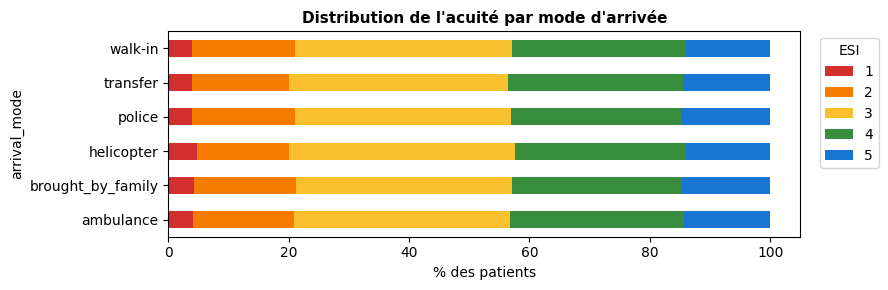

In [ ]:
# H2. Mode d'arrivée vs acuité — ambulance/hélicoptère attendus en ESI-1/2
if 'arrival_mode' in train.columns:
    ct_mode = pd.crosstab(train['arrival_mode'], train['triage_acuity'], normalize='index') * 100
    fig, ax = plt.subplots(figsize=(9, max(3, 0.4 * len(ct_mode))))
    ct_mode.plot(kind='barh', stacked=True, ax=ax, color=ESI_COLORS)
    ax.set_xlabel('% des patients')
    ax.set_title("Distribution de l'acuité par mode d'arrivée", fontsize=11, fontweight='bold')
    ax.legend(title='ESI', bbox_to_anchor=(1.02, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
else:
    print("Colonne 'arrival_mode' absente — bloc ignoré.")

### 3.3 Synthèse de l'EDA — ce que les résultats disent pour la modélisation

- **Données propres** : 0 valeur hors plage physiologique, 0 doublon, 0 chevauchement train/test, pas de dérive train/test (tests KS, p > 0.09 partout).
- **Signal concentré** : tous les signes vitaux sont très discriminants (Kruskal-Wallis, p ≈ 0) ; corrélations de Spearman avec l'acuité : `news2_score` −0.82, `gcs_total` +0.68, `temperature_c` −0.65, `pain_score` −0.63, `respiratory_rate` −0.62, `spo2` +0.61.
- **Très peu d'effet du contexte** : `age` (p = 0.68) et toutes les catégorielles sauf `mental_status_triage` (χ² = 45 388) sont non significatives (`sex`, `language`, `insurance_type`, `arrival_mode`, `shift`, `site_id`…). Le crowding et les comorbidités ont donc peu de chances d'apporter beaucoup : c'est ce que l'**ablation** de la section 6 vérifiera.
- **Multicolinéarité** : `pulse_pressure` et `mean_arterial_pressure` sont des combinaisons exactes de `systolic_bp` / `diastolic_bp` (VIF ≈ 10¹⁵) → à retirer pour les modèles linéaires.
- **Manquance** : `pain_score = -1` (non renseigné) pour ~14 % des patients (11 156 / 80 000) ; la manquance des signes vitaux est liée au niveau d'acuité (carte A4) → risque de raccourci « mesure absente = patient peu urgent » traité en section 10.
- **Texte** : un gradient de sévérité net dans les mots les plus fréquents (ESI-1 : *severe, shock, acute* ; ESI-5 : *advice, question, query, review, request*), alors que `chief_complaint_system` n'est pas significatif.

## 4. Feature Engineering (unique et cohérent train/test)

Une seule fonction construit **toutes** les features sur train+test concaténés (aucune étiquette n'est utilisée), puis les colonnes sont réparties en groupes pour pouvoir mesurer l'apport de chacun :

| Groupe | Contenu |
|---|---|
| `struct` | Features du baseline : signes vitaux imputés, flags de manquance, démographie, contexte d'arrivée, flags d'antécédents `hx_*`, indicateurs dérivés, one-hot de `mental_status_triage` |
| `missing` | **Complétude du bilan** : nombre de signes vitaux manquants, taux de complétude, manquants vitaux + douleur non renseignée |
| `temporal` | **Crowding** heure par heure (site × jour × heure), heure de pointe, interactions crowding × gravité / manquance, nuit × état mental altéré |
| `comorb` | **Comorbidités** : score pondéré (poids sur les vraies colonnes `hx_*`), comptes par système (cardiaque, respiratoire, métabolique-rénal, immuno-onco), embedding PCA |
| texte | TF-IDF (200 dimensions), ou embeddings MiniLM / BioClinicalBERT (section 5) |

In [ ]:
# ── Constantes de feature engineering ────────────────────────────────────
VITAL_COLS = ['systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure', 'shock_index',
              'heart_rate', 'respiratory_rate', 'temperature_c', 'spo2', 'gcs_total']

CAT_COLS = ['arrival_mode', 'arrival_day', 'arrival_season', 'shift', 'age_group', 'sex', 'language',
            'insurance_type', 'transport_origin', 'pain_location', 'mental_status_triage',
            'chief_complaint_system', 'site_id']

# Colonnes jamais utilisées comme features (identifiants, issues post-triage = fuite, cible)
DROP_COLS = ['patient_id', 'triage_nurse_id', 'chief_complaint_raw', 'disposition', 'ed_los_hours',
             'triage_acuity', '_is_train']

# Poids cliniques APPROXIMATIFS sur les vraies colonnes hx_* — à valider avec un avis clinique
# (ou à remplacer par l'importance SHAP). Colonnes absentes de ce dictionnaire : poids 1.0
CLINICAL_WEIGHTS = {
    'hx_heart_failure': 1.5, 'hx_coronary_artery_disease': 1.5, 'hx_ckd': 1.4,
    'hx_copd': 1.3, 'hx_stroke_prior': 1.3, 'hx_liver_disease': 1.3, 'hx_malignancy': 1.3,
    'hx_atrial_fibrillation': 1.2, 'hx_peripheral_vascular_disease': 1.2,
    'hx_immunosuppressed': 1.2, 'hx_coagulopathy': 1.2,
    'hx_diabetes_type1': 1.1, 'hx_diabetes_type2': 1.1, 'hx_dementia': 1.1, 'hx_hiv': 1.1,
}
COMORB_SYSTEMS = {
    'comorb_cardiac': ['hx_heart_failure', 'hx_coronary_artery_disease', 'hx_atrial_fibrillation',
                       'hx_hypertension', 'hx_peripheral_vascular_disease', 'hx_stroke_prior'],
    'comorb_resp': ['hx_copd', 'hx_asthma'],
    'comorb_metabolic_renal': ['hx_diabetes_type1', 'hx_diabetes_type2', 'hx_ckd', 'hx_obesity', 'hx_liver_disease'],
    'comorb_immuno_onco': ['hx_malignancy', 'hx_immunosuppressed', 'hx_hiv', 'hx_coagulopathy'],
}


def _safe_name(s):
    return re.sub(r'[^0-9a-zA-Z_]+', '_', str(s)).strip('_')


def build_features(train, test, history, cc, comorb_cols, seed=SEED):
    """Construit toutes les features sur train+test concaténés (aucune étiquette utilisée).
    Retourne un dict : F (features non textuelles), T (TF-IDF), groups, text, raw_vitals, is_train, tfidf, pca."""
    tr, te = train.copy(), test.copy()
    tr['_is_train'], te['_is_train'] = 1, 0
    df = pd.concat([tr, te], ignore_index=True, sort=False)
    n_rows = len(df)

    df = df.merge(history.drop_duplicates('patient_id'), on='patient_id', how='left', suffixes=('', '_hist'))
    df = df.merge(cc[['patient_id', 'chief_complaint_raw']].drop_duplicates('patient_id'), on='patient_id', how='left')
    df = df.drop(columns=[c for c in df.columns if c.endswith('_hist')])
    assert len(df) == n_rows, 'Jointure : le nombre de lignes a changé (doublons de patient_id ?)'
    is_train = (df['_is_train'].values == 1)

    vitals_present = [c for c in VITAL_COLS if c in df.columns]
    raw_vitals = df[vitals_present].copy()          # valeurs brutes (avant imputation), pour le garde-fou
    groups = {}

    # ── Manquance (avant toute imputation) ───────────────────────────────
    vit_with_na = [c for c in vitals_present if df[c].isnull().any()]
    for c in vit_with_na:
        df[f'{c}_missing'] = df[c].isnull().astype(int)
    df['pain_not_recorded'] = (df['pain_score'] == -1).astype(int)
    df['vitals_missing_count'] = raw_vitals.isnull().sum(axis=1)
    df['vitals_completeness'] = 1 - df['vitals_missing_count'] / max(len(vitals_present), 1)
    df['workup_missing_count'] = df['vitals_missing_count'] + df['pain_not_recorded']
    groups['missing'] = ['vitals_missing_count', 'vitals_completeness', 'workup_missing_count']

    # ── Imputation : médiane (age_group x shift), repli médiane globale ──
    df.loc[df['pain_score'] == -1, 'pain_score'] = np.nan
    grp = [c for c in ['age_group', 'shift'] if c in df.columns]
    for c in vit_with_na + ['pain_score']:
        if grp:
            df[c] = df.groupby(grp)[c].transform(lambda s: s.fillna(s.median()))
        df[c] = df[c].fillna(df[c].median())

    # ── Indicateurs dérivés (baseline) ───────────────────────────────────
    df['elderly']           = (df['age'] >= 65).astype(int)
    df['pediatric']         = (df['age'] < 16).astype(int)
    df['night_shift']       = (df['shift'] == 'night').astype(int)
    df['weekend']           = df['arrival_day'].isin(['Saturday', 'Sunday']).astype(int)
    df['high_risk_arrival'] = df['arrival_mode'].isin(['ambulance', 'helicopter']).astype(int)
    df['altered_ms']        = df['mental_status_triage'].isin(['confused', 'drowsy', 'unresponsive', 'agitated']).astype(int)
    # contrôle : les modalités codées en dur existent-elles vraiment ? (sinon l'indicateur serait toujours 0)
    print('mental_status_triage :', sorted(df['mental_status_triage'].astype(str).unique()), '| altered_ms=1 :', int(df['altered_ms'].sum()))
    print('arrival_mode         :', sorted(df['arrival_mode'].astype(str).unique()), '| high_risk_arrival=1 :', int(df['high_risk_arrival'].sum()))

    # one-hot de l'état mental (variable catégorielle la plus informative, χ² = 45 388)
    ms = pd.get_dummies(df['mental_status_triage'].astype(str), prefix='ms').astype(int)
    ms.columns = ['ms_' + _safe_name(c[3:]) for c in ms.columns]
    df = pd.concat([df, ms], axis=1)

    # ── Temporel / crowding ──────────────────────────────────────────────
    keys = [c for c in ['site_id', 'arrival_day', 'arrival_hour'] if c in df.columns]
    df['crowding_index'] = df.groupby(keys)['patient_id'].transform('count')
    if 'site_id' in df.columns:
        df['crowding_relative'] = df['crowding_index'] / df.groupby('site_id')['crowding_index'].transform('median')
    else:
        df['crowding_relative'] = df['crowding_index'] / df['crowding_index'].median()
    if 'arrival_hour' in df.columns:
        hourly = df['arrival_hour'].value_counts()
        df['peak_hour'] = df['arrival_hour'].isin(hourly[hourly >= hourly.quantile(0.75)].index).astype(int)
    else:
        df['peak_hour'] = 0
    df['crowding_x_news2']             = df['crowding_relative'] * df['news2_score']
    df['crowding_x_high_risk_arrival'] = df['crowding_relative'] * df['high_risk_arrival']
    df['crowding_x_missing']           = df['crowding_relative'] * df['vitals_missing_count']
    df['night_x_altered_ms']           = df['night_shift'] * df['altered_ms']
    groups['temporal'] = ['crowding_index', 'crowding_relative', 'peak_hour', 'crowding_x_news2',
                          'crowding_x_high_risk_arrival', 'crowding_x_missing', 'night_x_altered_ms']

    # ── Comorbidités ─────────────────────────────────────────────────────
    cm = [c for c in comorb_cols if c in df.columns]
    pca = None
    if cm:
        M = df[cm].fillna(0).values.astype(float)
        w = np.array([CLINICAL_WEIGHTS.get(c, 1.0) for c in cm])
        df['comorbidity_count'] = M.sum(axis=1)
        df['comorbidity_risk_score'] = (M * w).sum(axis=1)
        comorb_new = ['comorbidity_count', 'comorbidity_risk_score']
        for name, cols in COMORB_SYSTEMS.items():
            cols = [c for c in cols if c in cm]
            df[name] = df[cols].fillna(0).sum(axis=1) if cols else 0
            comorb_new.append(name)
        n_comp = min(4, len(cm))
        pca = PCA(n_components=n_comp, random_state=seed).fit(M[is_train])   # ajusté sur train uniquement
        emb = pca.transform(M)
        for i in range(n_comp):
            df[f'comorb_pca_{i + 1}'] = emb[:, i]
            comorb_new.append(f'comorb_pca_{i + 1}')
        print(f'PCA comorbidités : {n_comp} composantes, variance expliquée = {pca.explained_variance_ratio_.sum() * 100:.1f}%')
        groups['comorb'] = comorb_new
    else:
        groups['comorb'] = []

    # ── Encodage des catégorielles (ajusté sur train+test : codes cohérents) ──
    for c in CAT_COLS:
        if c in df.columns:
            df[c] = LabelEncoder().fit_transform(df[c].astype(str))

    # ── Matrice de features ──────────────────────────────────────────────
    F = df[[c for c in df.columns if c not in DROP_COLS]].copy()
    leftover = F.select_dtypes(exclude=[np.number, 'bool']).columns.tolist()   # filet de sécurité
    if leftover:
        print('Colonnes non numériques encodées automatiquement :', leftover)
        for c in leftover:
            F[c] = LabelEncoder().fit_transform(F[c].astype(str))
    for c in F.columns[F.isnull().any()]:                                       # NaN résiduels
        F[c] = F[c].fillna(F[c].median())
    special = {c for cols in groups.values() for c in cols}
    groups['struct'] = [c for c in F.columns if c not in special]

    # ── TF-IDF (vocabulaire ajusté sur train uniquement) ─────────────────
    text = df['chief_complaint_raw'].fillna('unknown').astype(str).values
    tfidf = TfidfVectorizer(max_features=200, ngram_range=(1, 2), min_df=5, sublinear_tf=True).fit(text[is_train])
    T = pd.DataFrame(tfidf.transform(text).toarray().astype('float32'),
                     columns=['cc_' + _safe_name(t) for t in tfidf.get_feature_names_out()])

    return dict(F=F, T=T, groups=groups, text=text, raw_vitals=raw_vitals, is_train=is_train,
                tfidf=tfidf, pca=pca, patient_id=df['patient_id'].values)


FE = build_features(train, test, history, cc, COMORB_COLS)
F, T_TFIDF, GROUPS = FE['F'], FE['T'], FE['groups']
TEXT_ALL, RAW_VITALS, IS_TRAIN = FE['text'], FE['raw_vitals'], FE['is_train']
tfidf_vec, comorb_pca = FE['tfidf'], FE['pca']

y_train = train['triage_acuity'].values - 1      # 0-indexé
assert (FE['patient_id'][:len(train)] == train['patient_id'].values).all()
assert IS_TRAIN[:len(train)].all() and not IS_TRAIN[len(train):].any()
assert F.isnull().sum().sum() == 0

print(f'\nF (non textuel) : {F.shape} | TF-IDF : {T_TFIDF.shape}')
for g, cols in GROUPS.items():
    print(f'  groupe {g:9s}: {len(cols):3d} colonnes')
print('Distribution des classes (train, %) :', (pd.Series(y_train).value_counts(normalize=True).sort_index() * 100).round(1).to_dict())

mental_status_triage : ['agitated', 'alert', 'confused', 'drowsy', 'unresponsive'] | altered_ms=1 : 42218
arrival_mode         : ['ambulance', 'brought_by_family', 'helicopter', 'police', 'transfer', 'walk-in'] | high_risk_arrival=1 : 30981
PCA comorbidités : 4 composantes, variance expliquée = 24.6%

F (non textuel) : (100000, 99) | TF-IDF : (100000, 200)
  groupe missing  :   3 colonnes
  groupe temporal :   7 colonnes
  groupe comorb   :  10 colonnes
  groupe struct   :  79 colonnes
Distribution des classes (train, %) : {0: 4.0, 1: 16.8, 2: 36.2, 3: 28.8, 4: 14.2}


In [ ]:
TEXT_BLOCKS = {'tfidf': T_TFIDF}     # dictionnaire nom -> DataFrame (toutes les lignes train+test)

def make_X(groups=('struct',), text=None):
    """Retourne (X_train, X_test) pour les groupes de features demandés (+ un bloc texte optionnel)."""
    cols = [c for g in groups for c in GROUPS[g]]
    parts = [F[cols]] + ([TEXT_BLOCKS[text]] if text else [])
    X_all = pd.concat(parts, axis=1)
    return X_all[IS_TRAIN].reset_index(drop=True), X_all[~IS_TRAIN].reset_index(drop=True)

X_struct, _ = make_X(('struct',))
print(f'X_struct : {X_struct.shape}')

X_struct : (80000, 79)


### 4.1 Utilitaires de validation croisée

Un seul protocole pour toutes les expériences (5-fold stratifié, même graine, donc des comparaisons équitables). En plus du QWK, on suit deux indicateurs de **sécurité** : le **rappel ESI-1** et le **taux de sous-triage critique** (vrais ESI-1/2 prédits ESI-4/5).

In [ ]:
def softmax_np(raw):
    raw = raw - raw.max(axis=1, keepdims=True)
    e = np.exp(raw)
    return e / e.sum(axis=1, keepdims=True)


def summarize(y, oof_prob, label):
    pred = oof_prob.argmax(axis=1)
    rec = recall_score(y, pred, labels=[0, 1, 2, 3, 4], average=None, zero_division=0)
    crit = np.isin(y, [0, 1])
    crit_miss = (crit & np.isin(pred, [3, 4])).sum() / max(crit.sum(), 1) * 100
    return dict(label=label, qwk=cohen_kappa_score(y, pred, weights='quadratic'),
                accuracy=accuracy_score(y, pred), f1_macro=f1_score(y, pred, average='macro', zero_division=0),
                recall_esi1=rec[0], recall_esi2=rec[1], crit_miss_pct=crit_miss,
                oof_prob=oof_prob, oof_pred=pred)


def _cv_core(X, y, fit_predict, X_test=None, n_folds=N_FOLDS, seed=SEED, label='model'):
    skf = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=seed)
    oof = np.zeros((len(X), 5))
    tst = np.zeros((len(X_test), 5)) if X_test is not None else None
    fold_qwk, models, t0 = [], [], time.time()
    for tr_idx, val_idx in skf.split(X, y):
        eval_sets = [X.iloc[val_idx]] + ([X_test] if X_test is not None else [])
        probs, model = fit_predict(X.iloc[tr_idx], y[tr_idx], eval_sets)
        oof[val_idx] = probs[0]
        if X_test is not None:
            tst += probs[1] / n_folds
        fold_qwk.append(cohen_kappa_score(y[val_idx], probs[0].argmax(axis=1), weights='quadratic'))
        models.append(model)
    res = summarize(y, oof, label)
    res.update(qwk_fold_mean=np.mean(fold_qwk), qwk_fold_std=np.std(fold_qwk),
               time_s=time.time() - t0, test_prob=tst, models=models)
    print(f'[{label:36s}] QWK={res["qwk"]:.4f} (plis {res["qwk_fold_mean"]:.4f}±{res["qwk_fold_std"]:.4f}) | '
          f'Rappel ESI-1={res["recall_esi1"]:.3f} | Sous-triage critique={res["crit_miss_pct"]:.2f}% | {res["time_s"]:.0f}s')
    return res


# Variables réellement continues (les seules à standardiser pour la régression logistique)
CONTINUOUS_COLS = ['age', 'pain_score', 'systolic_bp', 'diastolic_bp', 'mean_arterial_pressure', 'pulse_pressure',
                   'shock_index', 'respiratory_rate', 'temperature_c', 'news2_score', 'heart_rate', 'spo2',
                   'gcs_total', 'weight_kg', 'height_cm', 'bmi']


def run_cv(X, y, make_model, scale=False, label='model', X_test=None, keep_models=False):
    """CV générique pour un modèle scikit-learn-compatible (LogReg, RF, XGBoost, CatBoost, LightGBM...)."""
    scale_cols = [c for c in CONTINUOUS_COLS if c in X.columns] if scale else []

    def fit_predict(X_tr, y_tr, eval_sets):
        X_tr, evals = X_tr.copy(), [Z.copy() for Z in eval_sets]
        if scale_cols:
            X_tr = X_tr.astype({c: float for c in scale_cols})
            evals = [Z.astype({c: float for c in scale_cols}) for Z in evals]
            sc = StandardScaler().fit(X_tr[scale_cols])
            X_tr[scale_cols] = sc.transform(X_tr[scale_cols])
            for Z in evals:
                Z[scale_cols] = sc.transform(Z[scale_cols])
        m = make_model()
        m.fit(X_tr, y_tr)
        return [m.predict_proba(Z) for Z in evals], (m if keep_models else None)

    return _cv_core(X, y, fit_predict, X_test, label=label)

## 5. Étapes 2 et 3 du pipeline — Comparaison de modèles et comparaison NLP

### 5.1 Étape 2 — Comparaison de 5 familles de modèles (données structurées uniquement)

Résultats de votre exécution précédente (80 000 patients, features structurées uniquement) : XGBoost 0.9309, LightGBM 0.9299, CatBoost 0.9291, Random Forest 0.9268, Régression logistique 0.9158. Elles sont utilisées comme repli si `RUN_STRUCT_COMPARISON = False`.

In [ ]:
PREV_STRUCT = pd.DataFrame({     # résultats de l'exécution précédente (QWK OOF)
    'label': ['Structured | XGBoost', 'Structured | LightGBM', 'Structured | CatBoost',
              'Structured | RandomForest', 'Structured | LogisticRegression'],
    'qwk': [0.930925, 0.929944, 0.929060, 0.926821, 0.915815]})

# pulse_pressure et mean_arterial_pressure sont des combinaisons exactes de SBP/DBP (VIF ~ 1e15) :
# retirées pour la régression logistique (accélère aussi sa convergence)
LINEAR_DROP = [c for c in ('pulse_pressure', 'mean_arterial_pressure') if c in X_struct.columns]

model_factories = {
    'LogisticRegression': lambda: LogisticRegression(max_iter=1000, class_weight='balanced', C=1.0, random_state=SEED),
    'RandomForest': lambda: RandomForestClassifier(n_estimators=RF_TREES, min_samples_leaf=5,
                                                   class_weight='balanced', n_jobs=-1, random_state=SEED),
    'XGBoost': lambda: xgb.XGBClassifier(objective='multi:softprob', num_class=5, n_estimators=N_TREES_CMP,
                                         learning_rate=0.05, max_depth=6, subsample=0.85, colsample_bytree=0.85,
                                         reg_lambda=0.1, tree_method='hist', random_state=SEED, verbosity=0),
    'LightGBM': lambda: lgb.LGBMClassifier(objective='multiclass', num_class=5, n_estimators=N_TREES_CMP,
                                           learning_rate=0.05, num_leaves=63, subsample=0.85, subsample_freq=1,
                                           colsample_bytree=0.85, class_weight='balanced', random_state=SEED, verbose=-1),
    'CatBoost': lambda: CatBoostClassifier(loss_function='MultiClass', iterations=N_TREES_CMP, learning_rate=0.05,
                                           depth=6, auto_class_weights='Balanced', random_state=SEED, verbose=False),
}

structured_results = []
if RUN_STRUCT_COMPARISON:
    for name, factory in model_factories.items():
        X_in = X_struct.drop(columns=LINEAR_DROP) if name == 'LogisticRegression' else X_struct
        structured_results.append(run_cv(X_in, y_train, factory, scale=(name == 'LogisticRegression'),
                                         label=f'Structured | {name}'))
    structured_df = pd.DataFrame(structured_results).sort_values('qwk', ascending=False)
else:
    structured_df = PREV_STRUCT.copy()

structured_df[['label', 'qwk']].reset_index(drop=True)

,label,qwk
0,Structured | XGBoost,0.930925
1,Structured | LightGBM,0.929944
2,Structured | CatBoost,0.929060
3,Structured | RandomForest,0.926821
4,Structured | LogisticRegression,0.915815


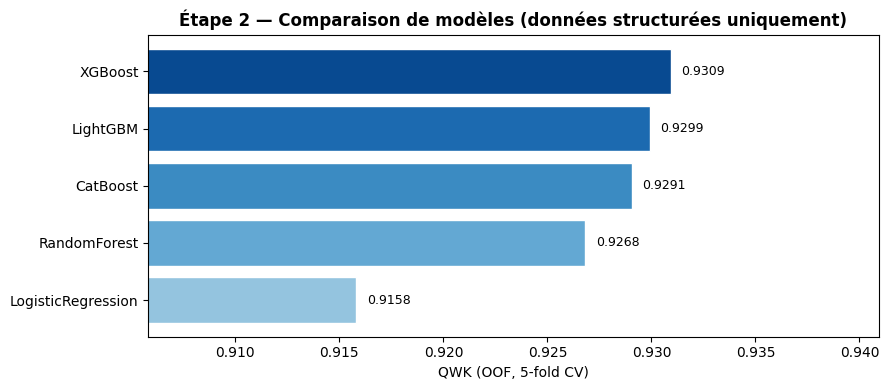

Meilleur modèle structuré : Structured | XGBoost (QWK=0.9309)
Écart faible entre XGBoost / LightGBM / CatBoost : le choix de la famille de modèles compte moins que les features.


In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
plot_df = structured_df.sort_values('qwk')
ax.barh(plot_df['label'].str.replace('Structured | ', '', regex=False), plot_df['qwk'],
        color=plt.cm.Blues(np.linspace(0.4, 0.9, len(plot_df))), edgecolor='white')
for i, v in enumerate(plot_df['qwk']):
    ax.text(v + 0.0005, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlim(plot_df['qwk'].min() - 0.01, plot_df['qwk'].max() + 0.01)
ax.set_xlabel('QWK (OOF, 5-fold CV)')
ax.set_title('Étape 2 — Comparaison de modèles (données structurées uniquement)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

best_struct_label = structured_df.iloc[0]['label']
print(f'Meilleur modèle structuré : {best_struct_label} (QWK={structured_df.iloc[0]["qwk"]:.4f})')
print('Écart faible entre XGBoost / LightGBM / CatBoost : le choix de la famille de modèles compte moins que les features.')

In [ ]:
# Analyse détaillée du meilleur modèle (uniquement si la comparaison vient d'être exécutée)
if structured_results:
    best_res = max(structured_results, key=lambda r: r['qwk'])
    print(f'Rapport de classification (OOF) — {best_res["label"]}')
    print(classification_report(y_train, best_res['oof_pred'], target_names=TARGET_NAMES, digits=3))
else:
    print('Comparaison sautée (RUN_STRUCT_COMPARISON = False) : pas de rapport détaillé.')

Comparaison sautée (RUN_STRUCT_COMPARISON = False) : pas de rapport détaillé.


### 5.2 Étape 3 — Comparaison NLP (texte de la plainte uniquement)

On compare TF-IDF (baseline), MiniLM (`all-MiniLM-L6-v2`, 384 dim) et BioClinicalBERT (768 dim) avec un classificateur LightGBM **identique**, pour isoler l'effet de la représentation.

**Pourquoi c'était lent avant, et ce qui change :**
- les plaintes sont très répétitives (textes à gabarit) : on n'encode que les **textes uniques**, puis on redistribue — gain typique de ×10 à ×100 ;
- les embeddings sont **mis en cache** sur disque (`ARTIFACT_DIR`) : plus de recalcul d'une session à l'autre ;
- ils sont calculés pour **train et test** (indispensable pour la soumission) ;
- les embeddings sont réduits à `EMB_PCA_DIMS` dimensions par PCA (ajustée sur train) pour que LightGBM reste rapide et que la comparaison avec TF-IDF (200 dim) soit équitable.

Les avertissements « UNEXPECTED / unused weights » au chargement de BioClinicalBERT sont normaux : on charge l'encodeur seul, sans sa tête de prédiction (MLM).

In [ ]:

import socket, glob

def _internet_ok(host='huggingface.co', port=443, timeout=3):
    try:
        socket.create_connection((host, port), timeout=timeout).close()
        return True
    except OSError:
        return False

# Sans cache d'embeddings ET sans internet (ex. Kaggle hors ligne) : on désactive les embeddings au lieu de planter
_has_cache = bool(glob.glob(os.path.join(ARTIFACT_DIR, 'emb_*.npy')))
if (RUN_MINILM or RUN_BCB) and not _has_cache and not _internet_ok():
    print('⚠ Pas de cache d\'embeddings et pas d\'accès à huggingface.co : RUN_MINILM / RUN_BCB désactivés (TF-IDF seulement).')
    RUN_MINILM = RUN_BCB = False

n_unique = len(np.unique(TEXT_ALL))
print(f'{len(TEXT_ALL):,} plaintes dont {n_unique:,} textes uniques ({n_unique / len(TEXT_ALL) * 100:.1f}%)')
print('Exemples :', list(TEXT_ALL[:3]))

DEVICE = 'cpu'
if RUN_MINILM or RUN_BCB:
    for mod, pip_name in {'sentence_transformers': 'sentence-transformers', 'transformers': 'transformers'}.items():
        if importlib.util.find_spec(mod) is None:
            subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pip_name])
    import torch
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Device embeddings : {DEVICE}' + ('  (activez un GPU : Exécution > Modifier le type d\'exécution)' if DEVICE == 'cpu' and (RUN_MINILM or RUN_BCB) else ''))

100,000 plaintes dont 4,979 textes uniques (5.0%)
Exemples : ['thunderclap headache, worsening with movement', 'contraception advice, intermittent', 'general health question, intermittent']
Device embeddings : cpu  (activez un GPU : Exécution > Modifier le type d'exécution)


In [ ]:
def embed_unique(name, texts, encode_fn):
    """Encode uniquement les textes uniques, avec cache disque, puis redistribue sur toutes les lignes."""
    uniq, inv = np.unique(np.asarray(texts).astype(str), return_inverse=True)
    h = hashlib.md5('\n'.join(uniq).encode('utf-8')).hexdigest()[:10]
    path = os.path.join(ARTIFACT_DIR, f'emb_{name}_{h}.npy')
    if os.path.exists(path):
        emb_u = np.load(path)
        print(f'[{name}] chargé depuis le cache ({len(uniq):,} textes uniques)')
    else:
        t0 = time.time()
        emb_u = np.asarray(encode_fn(list(uniq)), dtype='float32')
        np.save(path, emb_u)
        print(f'[{name}] {len(uniq):,} textes uniques encodés en {time.time() - t0:.0f}s')
    return emb_u[inv]


def encode_minilm(texts):
    from sentence_transformers import SentenceTransformer
    return SentenceTransformer('all-MiniLM-L6-v2', device=DEVICE).encode(
        texts, batch_size=128, show_progress_bar=True, convert_to_numpy=True)


def encode_bcb(texts, name='emilyalsentzer/Bio_ClinicalBERT', batch_size=64, max_length=64):
    import torch
    from transformers import AutoTokenizer, AutoModel
    tok = AutoTokenizer.from_pretrained(name)
    model = AutoModel.from_pretrained(name).to(DEVICE).eval()
    lens = np.array([len(tok.encode(t)) for t in texts[:3000]])
    print(f'Longueur en tokens : moyenne {lens.mean():.1f}, max {lens.max()}, '
          f'{(lens > max_length).mean() * 100:.1f}% > {max_length} (tronqués)')
    out = []
    with torch.no_grad():
        for i in range(0, len(texts), batch_size):
            enc = tok(texts[i:i + batch_size], padding=True, truncation=True,
                      max_length=max_length, return_tensors='pt').to(DEVICE)
            h = model(**enc).last_hidden_state
            m = enc['attention_mask'].unsqueeze(-1).float()
            out.append(((h * m).sum(1) / m.sum(1).clamp(min=1e-9)).cpu().numpy())   # mean pooling masqué
    return np.vstack(out)


def to_block(prefix, emb):
    """DataFrame de features à partir des embeddings, avec réduction PCA ajustée sur train."""
    if EMB_PCA_DIMS and emb.shape[1] > EMB_PCA_DIMS:
        p = PCA(n_components=EMB_PCA_DIMS, random_state=SEED).fit(emb[IS_TRAIN])
        print(f'  PCA {prefix}: {emb.shape[1]} -> {EMB_PCA_DIMS} dims ({p.explained_variance_ratio_.sum() * 100:.1f}% de variance)')
        emb = p.transform(emb)
    return pd.DataFrame(emb.astype('float32'), columns=[f'{prefix}_{i}' for i in range(emb.shape[1])])


if RUN_MINILM:
    TEXT_BLOCKS['minilm'] = to_block('minilm', embed_unique('minilm', TEXT_ALL, encode_minilm))
if RUN_BCB:
    TEXT_BLOCKS['bcb'] = to_block('bcb', embed_unique('bioclinicalbert', TEXT_ALL, encode_bcb))
print('Blocs texte disponibles :', {k: v.shape for k, v in TEXT_BLOCKS.items()})

[minilm] chargé depuis le cache (4,979 textes uniques)
  PCA minilm: 384 -> 64 dims (80.7% de variance)
[bioclinicalbert] chargé depuis le cache (4,979 textes uniques)
  PCA bcb: 768 -> 64 dims (85.9% de variance)
Blocs texte disponibles : {'tfidf': (100000, 200), 'minilm': (100000, 64), 'bcb': (100000, 64)}


[TF-IDF Only                         ] QWK=0.8253 (plis 0.8253±0.0028) | Rappel ESI-1=0.895 | Sous-triage critique=0.00% | 341s
[MiniLM Only                         ] QWK=0.9991 (plis 0.9991±0.0003) | Rappel ESI-1=0.990 | Sous-triage critique=0.01% | 202s
[BioClinicalBERT Only                ] QWK=0.9992 (plis 0.9992±0.0003) | Rappel ESI-1=0.990 | Sous-triage critique=0.01% | 207s


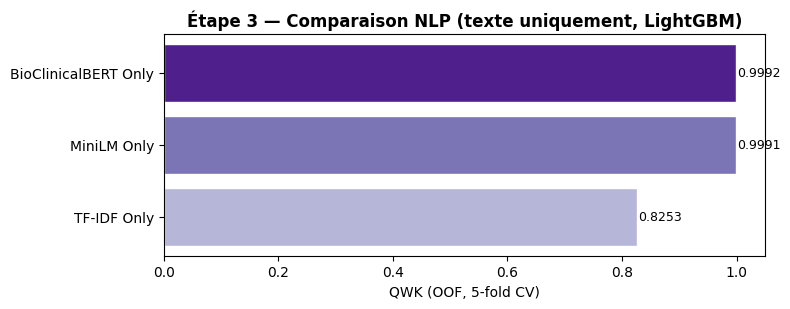

Meilleure représentation textuelle : BioClinicalBERT Only (QWK=0.9992)
Bloc texte utilisé pour la fusion et le modèle final : bcb


,label,qwk,recall_esi1,crit_miss_pct,time_s
0,BioClinicalBERT Only,0.999163,0.990068,0.006002,206.606883
1,MiniLM Only,0.999146,0.990068,0.006002,202.302720
2,TF-IDF Only,0.825330,0.895407,0.000000,340.988950


In [ ]:
def lgbm_balanced_factory(params=None):
    p = dict(LGB_FAST if params is None else params)
    n = p.pop('n_estimators')
    return lambda: lgb.LGBMClassifier(n_estimators=n, class_weight='balanced', random_state=SEED, **p)

NLP_LABELS = {'tfidf': 'TF-IDF Only', 'minilm': 'MiniLM Only', 'bcb': 'BioClinicalBERT Only'}
text_results = []
for key, block in TEXT_BLOCKS.items():
    Xt = block[IS_TRAIN].reset_index(drop=True)
    r = run_cv(Xt, y_train, lgbm_balanced_factory(), label=NLP_LABELS[key])
    r['key'] = key
    text_results.append(r)

text_df = pd.DataFrame(text_results).sort_values('qwk', ascending=False)
best_text_key = text_df.iloc[0]['key']
FINAL_TEXT_NAME = best_text_key if FINAL_TEXT == 'auto' else FINAL_TEXT
assert FINAL_TEXT_NAME in TEXT_BLOCKS, f'FINAL_TEXT={FINAL_TEXT!r} indisponible (blocs : {list(TEXT_BLOCKS)})'

fig, ax = plt.subplots(figsize=(8, 3.2))
plot_df = text_df.sort_values('qwk')
ax.barh(plot_df['label'], plot_df['qwk'], color=plt.cm.Purples(np.linspace(0.4, 0.9, len(plot_df))), edgecolor='white')
for i, v in enumerate(plot_df['qwk']):
    ax.text(v + 0.002, i, f'{v:.4f}', va='center', fontsize=9)
ax.set_xlabel('QWK (OOF, 5-fold CV)')
ax.set_title('Étape 3 — Comparaison NLP (texte uniquement, LightGBM)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'Meilleure représentation textuelle : {NLP_LABELS[best_text_key]} (QWK={text_df.iloc[0]["qwk"]:.4f})')
print(f'Bloc texte utilisé pour la fusion et le modèle final : {FINAL_TEXT_NAME}')
text_df[['label', 'qwk', 'recall_esi1', 'crit_miss_pct', 'time_s']].reset_index(drop=True)

### 5.3 Diagnostic de fuite — le texte de la plainte reconstitue-t-il l'acuité ?

Constat de l'étape précédente : **texte seul → QWK ≈ 0.999**, alors que **toutes les features structurées → ≈ 0.93**. Avec seulement ~5 % de textes uniques, la plainte semble générée à partir de gabarits liés au niveau d'acuité (jeu synthétique). Ce test mesure la limite : une simple **table de correspondance « texte exact → acuité majoritaire »**, évaluée en validation croisée, sans aucun modèle.

In [ ]:
txt_tr, txt_te = TEXT_ALL[IS_TRAIN], TEXT_ALL[~IS_TRAIN]
df_t = pd.DataFrame({'text': txt_tr, 'y': y_train})

share_te_seen = pd.Series(txt_te).isin(set(txt_tr)).mean() * 100
print(f'Textes uniques (train) : {df_t["text"].nunique():,} | plaintes du test dont le texte exact existe dans train : {share_te_seen:.1f}%')

# Pureté : part de la classe majoritaire à l'intérieur de chaque texte unique
g = df_t.groupby('text')['y']
purity = g.agg(lambda s: s.value_counts(normalize=True).iloc[0])
size = g.size()
print(f'Pureté moyenne (pondérée par la fréquence) : {(purity * size).sum() / size.sum() * 100:.1f}%  (100% = le texte détermine l\'acuité)')

# Table de correspondance en validation croisée : texte -> acuité majoritaire du pli d'entraînement
skf_lk = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof_lk = np.zeros(len(df_t), dtype=int)
for tr_i, va_i in skf_lk.split(df_t, df_t['y']):
    maj = df_t.iloc[tr_i].groupby('text')['y'].agg(lambda s: s.value_counts().index[0])
    fallback = int(pd.Series(y_train[tr_i]).mode()[0])
    oof_lk[va_i] = df_t['text'].iloc[va_i].map(maj).fillna(fallback).astype(int).values

qwk_lk = cohen_kappa_score(y_train, oof_lk, weights='quadratic')
acc_lk = accuracy_score(y_train, oof_lk)
print(f'\nTable de correspondance texte -> acuité (CV 5 plis) : QWK = {qwk_lk:.4f} | accuracy = {acc_lk:.4f}')
if qwk_lk > 0.95:
    print('⚠ Le texte à lui seul reconstitue (quasi) l\'acuité : forte suspicion d\'artefact de génération synthétique.\n'
          '  -> Le QWK avec texte ne reflète pas une performance clinique ; voir le modèle SANS texte (section 7.1).')
else:
    print('Le texte seul reste loin de reconstituer l\'acuité : pas de signe de fuite évident.')

Textes uniques (train) : 4,949 | plaintes du test dont le texte exact existe dans train : 99.8%
Pureté moyenne (pondérée par la fréquence) : 99.9%  (100% = le texte détermine l'acuité)

Table de correspondance texte -> acuité (CV 5 plis) : QWK = 0.9932 | accuracy = 0.9959
⚠ Le texte à lui seul reconstitue (quasi) l'acuité : forte suspicion d'artefact de génération synthétique.
  -> Le QWK avec texte ne reflète pas une performance clinique ; voir le modèle SANS texte (section 7.1).


## 6. Étape 4 du pipeline — Fusion multimodale et corrections des limitations

### 6.1 Ablation : quels groupes de features améliorent vraiment le modèle ?

On part du baseline (**structuré + TF-IDF**) puis on ajoute **un groupe à la fois** (manquance, temporel/crowding, comorbidités), toujours avec le même LightGBM équilibré (`class_weight='balanced'`) et les mêmes plis. Chaque groupe est comparé sur le **QWK**, le **rappel ESI-1** et le **sous-triage critique** — un groupe n'est conservé que s'il aide.

In [ ]:
abl_specs = [
    ('base',     'Baseline : struct + TF-IDF',      ('struct',),                 'tfidf'),
    ('missing',  '+ complétude du bilan (manquance)', ('struct', 'missing'),     'tfidf'),
    ('temporal', '+ temporel / crowding',           ('struct', 'temporal'),      'tfidf'),
    ('comorb',   '+ comorbidités enrichies',        ('struct', 'comorb'),        'tfidf'),
]
if FINAL_TEXT_NAME != 'tfidf':   # on repart d'un bloc texte plus riche si l'étape 3 l'a désigné
    abl_specs = [(k, l, g, FINAL_TEXT_NAME if k != 'base' else 'tfidf') for k, l, g, _ in abl_specs]
    abl_specs.insert(1, ('base_text', f'Base : struct + {FINAL_TEXT_NAME}', ('struct',), FINAL_TEXT_NAME))

abl = {}
for key, label, groups, text in abl_specs:
    Xa, _ = make_X(groups, text)
    abl[key] = run_cv(Xa, y_train, lgbm_balanced_factory(), label=label)

ref_key = 'base_text' if 'base_text' in abl else 'base'
abl_table = pd.DataFrame([{**{k: r[k] for k in ('label', 'qwk', 'recall_esi1', 'recall_esi2', 'crit_miss_pct')},
                           'delta_qwk': r['qwk'] - abl[ref_key]['qwk'],
                           'delta_recall_esi1': r['recall_esi1'] - abl[ref_key]['recall_esi1']} for r in abl.values()])
abl_table.round(4)

[Baseline : struct + TF-IDF          ] QWK=0.9950 (plis 0.9950±0.0002) | Rappel ESI-1=0.955 | Sous-triage critique=0.02% | 352s
[Base : struct + bcb                 ] QWK=0.9996 (plis 0.9996±0.0001) | Rappel ESI-1=0.990 | Sous-triage critique=0.01% | 452s
[+ complétude du bilan (manquance)   ] QWK=0.9997 (plis 0.9997±0.0001) | Rappel ESI-1=0.991 | Sous-triage critique=0.01% | 425s
[+ temporel / crowding               ] QWK=0.9996 (plis 0.9996±0.0001) | Rappel ESI-1=0.991 | Sous-triage critique=0.01% | 417s
[+ comorbidités enrichies            ] QWK=0.9997 (plis 0.9997±0.0001) | Rappel ESI-1=0.991 | Sous-triage critique=0.01% | 492s


,label,qwk,recall_esi1,recall_esi2,crit_miss_pct,delta_qwk,delta_recall_esi1
0,Baseline : struct + TF-IDF,0.9950,0.9550,0.9863,0.018,-0.0046,-0.0348
1,Base : struct + bcb,0.9996,0.9898,0.9981,0.006,0.0000,0.0000
2,+ complétude du bilan (manquance),0.9997,0.9910,0.9984,0.012,0.0000,0.0012
3,+ temporel / crowding,0.9996,0.9910,0.9977,0.012,-0.0000,0.0012
4,+ comorbidités enrichies,0.9997,0.9907,0.9980,0.006,0.0000,0.0009


In [ ]:
# Décision automatique : on garde un groupe s'il améliore le QWK d'au moins 0.0005 ou le rappel ESI-1 d'au moins 0.005
USE_GROUPS = ['struct']
for g in ('missing', 'temporal', 'comorb'):
    r, ref = abl[g], abl[ref_key]
    d_qwk, d_rec = r['qwk'] - ref['qwk'], r['recall_esi1'] - ref['recall_esi1']
    keep = (d_qwk >= 0.0005) or (d_rec >= 0.005)
    print(f'  groupe {g:9s}: ΔQWK={d_qwk:+.5f} | Δrappel ESI-1={d_rec:+.4f} -> {"CONSERVÉ" if keep else "écarté"}')
    if keep:
        USE_GROUPS.append(g)
if FORCE_GROUPS is not None:
    USE_GROUPS = ['struct'] + [g for g in FORCE_GROUPS if g != 'struct']
print('\nGroupes retenus :', USE_GROUPS, '| bloc texte :', FINAL_TEXT_NAME)
print('Rappel : un ΔQWK de l\'ordre de 0.001 est dans le bruit ; ne sur-interprétez pas les petits écarts.')

  groupe missing  : ΔQWK=+0.00003 | Δrappel ESI-1=+0.0012 -> écarté
  groupe temporal : ΔQWK=-0.00003 | Δrappel ESI-1=+0.0012 -> écarté
  groupe comorb   : ΔQWK=+0.00002 | Δrappel ESI-1=+0.0009 -> écarté

Groupes retenus : ['struct'] | bloc texte : bcb
Rappel : un ΔQWK de l'ordre de 0.001 est dans le bruit ; ne sur-interprétez pas les petits écarts.


### 6.2 Limitation 1 — Déséquilibre de classe (ESI-1 ≈ 4 %)

ESI-1 est la classe la plus rare **et** la plus critique. Trois stratégies sont comparées sur l'ensemble de features retenu :

- **balanced** : `class_weight='balanced'` (référence)
- **oversample** : duplication aléatoire de ESI-1 et ESI-2 (×3) dans chaque pli d'entraînement uniquement
- **focal** : focal loss (γ = 2) pondérée par la fréquence inverse des classes, via un objectif personnalisé LightGBM. Le gradient est une approximation classique (le facteur focal est traité comme un poids constant). **Expérimental** : à valider sur vos résultats.

**Règle de choix automatique** : parmi les stratégies dont le QWK est à moins de 0.005 du meilleur, on retient celle qui maximise le **rappel ESI-1** (puis le QWK).

In [ ]:
def oversample(X_tr, y_tr, classes=(0, 1), factor=3, seed=SEED):
    """Duplique avec remise les classes cibles dans le pli d'entraînement uniquement."""
    rng = np.random.RandomState(seed)
    Xs, ys = [X_tr], [y_tr]
    for c in classes:
        idx = np.where(y_tr == c)[0]
        if len(idx):
            pick = rng.choice(idx, size=len(idx) * (factor - 1), replace=True)
            Xs.append(X_tr.iloc[pick]); ys.append(y_tr[pick])
    return pd.concat(Xs, axis=0).reset_index(drop=True), np.concatenate(ys)


def make_focal_objective(alpha, gamma=2.0, K=5):
    """Objectif multiclasse personnalisé (LightGBM >= 4 : passé via params['objective'])."""
    def objective(preds, dataset):
        y = dataset.get_label().astype(int)
        n = len(y)
        flat = (preds.ndim == 1)
        P = softmax_np(preds.reshape(n, K, order='F') if flat else preds)
        Y = np.eye(K)[y]
        pt = np.clip((P * Y).sum(axis=1, keepdims=True), 1e-7, 1 - 1e-7)
        w = ((1 - pt) ** gamma) * alpha[y][:, None]          # poids focal x poids de classe
        grad = w * (P - Y)
        hess = np.clip(w * P * (1 - P), 1e-6, None)
        return (grad.ravel(order='F'), hess.ravel(order='F')) if flat else (grad, hess)
    return objective


def cv_lgbm(X, y, strategy='balanced', params=None, X_test=None, label=None, keep_models=False, seed=SEED):
    """CV LightGBM avec stratégie anti-déséquilibre ('balanced' | 'oversample' | 'focal')."""
    params = dict(LGB_FAST if params is None else params)
    n_trees = params.pop('n_estimators')
    label = label or f'LightGBM | {strategy}'

    def fit_predict(X_tr, y_tr, eval_sets):
        if strategy == 'balanced':
            m = lgb.LGBMClassifier(n_estimators=n_trees, class_weight='balanced', random_state=seed, **params)
            m.fit(X_tr, y_tr)
            return [m.predict_proba(Z) for Z in eval_sets], (m if keep_models else None)
        if strategy == 'oversample':
            Xo, yo = oversample(X_tr, y_tr, seed=seed)
            m = lgb.LGBMClassifier(n_estimators=n_trees, random_state=seed, **params)
            m.fit(Xo, yo)
            return [m.predict_proba(Z) for Z in eval_sets], (m if keep_models else None)
        if strategy == 'focal':
            counts = np.bincount(y_tr, minlength=5)
            alpha = len(y_tr) / (5 * np.maximum(counts, 1))
            p = dict(objective=make_focal_objective(alpha), num_class=5, learning_rate=params['learning_rate'],
                     num_leaves=params['num_leaves'], bagging_fraction=params['subsample'],
                     bagging_freq=params['subsample_freq'], feature_fraction=params['colsample_bytree'],
                     lambda_l1=params['reg_alpha'], lambda_l2=params['reg_lambda'],
                     min_data_in_leaf=params['min_child_samples'], num_threads=params['n_jobs'],
                     verbose=-1, seed=seed)
            booster = lgb.train(p, lgb.Dataset(X_tr, label=y_tr), num_boost_round=n_trees)
            return [softmax_np(booster.predict(Z, raw_score=True)) for Z in eval_sets], (booster if keep_models else None)
        raise ValueError(strategy)

    return _cv_core(X, y, fit_predict, X_test, label=label)

Matrice retenue : (80000, 143) (groupes ['struct'] + texte bcb)
[Stratégie : balanced                ] QWK=0.9996 (plis 0.9996±0.0001) | Rappel ESI-1=0.990 | Sous-triage critique=0.01% | 449s
[Stratégie : oversample              ] QWK=0.9995 (plis 0.9995±0.0001) | Rappel ESI-1=0.986 | Sous-triage critique=0.02% | 490s
[Stratégie : focal                   ] QWK=0.9993 (plis 0.9993±0.0002) | Rappel ESI-1=0.989 | Sous-triage critique=0.02% | 306s


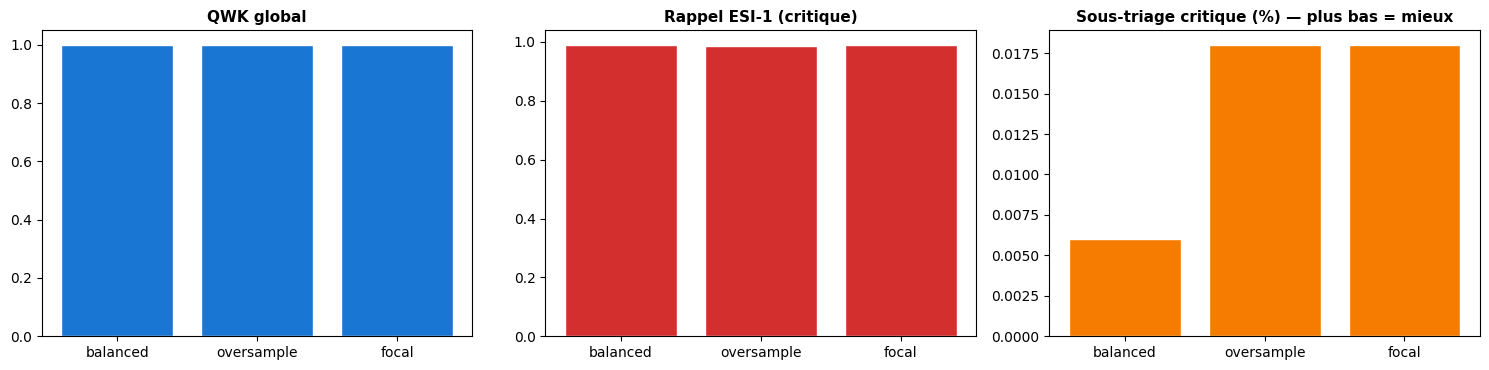

Stratégie retenue : balanced


,label,qwk,recall_esi1,recall_esi2,crit_miss_pct
0,Stratégie : balanced,0.9996,0.9898,0.9981,0.006
1,Stratégie : oversample,0.9995,0.9860,0.9982,0.018
2,Stratégie : focal,0.9993,0.9885,0.9949,0.018


In [ ]:
TEXT_FOR_FINAL = FINAL_TEXT_NAME if USE_TEXT_IN_FINAL else None
X_sel_tr, X_sel_te = make_X(tuple(USE_GROUPS), TEXT_FOR_FINAL)
print(f'Matrice retenue : {X_sel_tr.shape} (groupes {USE_GROUPS} + texte {TEXT_FOR_FINAL})')

strategy_results = {s: cv_lgbm(X_sel_tr, y_train, strategy=s, label=f'Stratégie : {s}')
                    for s in ('balanced', 'oversample', 'focal')}

strat_df = pd.DataFrame([{k: r[k] for k in ('label', 'qwk', 'recall_esi1', 'recall_esi2', 'crit_miss_pct')}
                         for r in strategy_results.values()])
best_qwk = strat_df['qwk'].max()
eligible = {s: r for s, r in strategy_results.items() if r['qwk'] >= best_qwk - 0.005}
FINAL_STRATEGY = max(eligible, key=lambda s: (eligible[s]['recall_esi1'], eligible[s]['qwk']))
if FORCE_STRATEGY is not None:
    FINAL_STRATEGY = FORCE_STRATEGY

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, title, colr in zip(axes, ['qwk', 'recall_esi1', 'crit_miss_pct'],
                                ['QWK global', 'Rappel ESI-1 (critique)', 'Sous-triage critique (%) — plus bas = mieux'],
                                ['#1976d2', '#d32f2f', '#f57c00']):
    ax.bar(strat_df['label'].str.replace('Stratégie : ', ''), strat_df[col], color=colr, edgecolor='white')
    ax.set_title(title, fontsize=11, fontweight='bold')
plt.tight_layout(); plt.show()

print(f'Stratégie retenue : {FINAL_STRATEGY}')
strat_df.round(4)

## 7. Model Training — modèle final (LightGBM, 5-fold, OOF et test)

Le meilleur ensemble de features et la meilleure stratégie sont ré-entraînés avec les hyperparamètres complets (`LGB_FINAL`). Les prédictions **OOF** (pour l'évaluation) et **test** (moyenne des 5 plis, pour la soumission) sont produites dans le même passage — cette cellule remplace l'ancienne section « Model Training » qui n'existait plus dans le notebook.

In [ ]:
final_res = cv_lgbm(X_sel_tr, y_train, strategy=FINAL_STRATEGY, params=LGB_FINAL, X_test=X_sel_te,
                    label=f'MODÈLE FINAL ({FINAL_STRATEGY})', keep_models=True)

oof_prob, test_prob = final_res['oof_prob'], final_res['test_prob']
oof_labels = final_res['oof_pred']
print(f'\nQWK OOF = {final_res["qwk"]:.4f} | QWK par pli = {final_res["qwk_fold_mean"]:.4f} ± {final_res["qwk_fold_std"]:.4f}')
print(f'Features : {X_sel_tr.shape[1]} | prédictions test : {test_prob.shape}')

[MODÈLE FINAL (balanced)             ] QWK=0.9995 (plis 0.9995±0.0001) | Rappel ESI-1=0.987 | Sous-triage critique=0.01% | 818s

QWK OOF = 0.9995 | QWK par pli = 0.9995 ± 0.0001
Features : 143 | prédictions test : (20000, 5)


### 7.1 Robustesse : modèle sans texte et CV groupée par plainte

- **Sans texte** : même pipeline, uniquement les features structurées retenues. C'est la référence cliniquement la plus réaliste si le texte est un artefact de génération (5.3).
- **CV groupée** : les plaintes au texte identique sont toutes dans le même pli ; le modèle est donc évalué sur des **textes jamais vus**. Si le QWK s'effondre vers le niveau « sans texte », le modèle mémorisait des gabarits.

In [ ]:
# ── Modèle SANS texte (référence clinique) ───────────────────────────────
if USE_TEXT_IN_FINAL:
    X_nt_tr, X_nt_te = make_X(tuple(USE_GROUPS), None)
    notext_res = cv_lgbm(X_nt_tr, y_train, strategy=FINAL_STRATEGY, params=LGB_FINAL, X_test=X_nt_te,
                         label=f'SANS TEXTE ({FINAL_STRATEGY})')
else:
    notext_res, X_nt_tr, X_nt_te = final_res, X_sel_tr, X_sel_te       # le modèle final est déjà sans texte

# ── CV groupée par texte de plainte (modèle avec texte, hyperparamètres rapides) ──
grouped_res = None
if RUN_GROUPED_CV and FINAL_TEXT_NAME in TEXT_BLOCKS:
    from sklearn.model_selection import StratifiedGroupKFold
    Xg, _ = make_X(tuple(USE_GROUPS), FINAL_TEXT_NAME)
    groups_txt = pd.factorize(TEXT_ALL[IS_TRAIN])[0]
    sgkf = StratifiedGroupKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
    oof_g, t0 = np.zeros((len(Xg), 5)), time.time()
    for tr_i, va_i in sgkf.split(Xg, y_train, groups=groups_txt):
        m = lgbm_balanced_factory()()
        m.fit(Xg.iloc[tr_i], y_train[tr_i])
        oof_g[va_i] = m.predict_proba(Xg.iloc[va_i])
    grouped_res = summarize(y_train, oof_g, f'Avec texte ({FINAL_TEXT_NAME}), CV groupée par plainte')
    print(f'CV groupée terminée en {time.time() - t0:.0f}s')

cands = [final_res, notext_res] + ([grouped_res] if grouped_res is not None else [])
robust_df = pd.DataFrame([{k: r[k] for k in ('label', 'qwk', 'recall_esi1', 'recall_esi2', 'crit_miss_pct')} for r in cands])
print('\nComparaison de robustesse (OOF) :')
robust_df.round(4)

[SANS TEXTE (balanced)               ] QWK=0.9313 (plis 0.9313±0.0011) | Rappel ESI-1=0.939 | Sous-triage critique=0.00% | 401s
CV groupée terminée en 459s

Comparaison de robustesse (OOF) :


,label,qwk,recall_esi1,recall_esi2,crit_miss_pct
0,MODÈLE FINAL (balanced),0.9995,0.9873,0.9976,0.012
1,SANS TEXTE (balanced),0.9313,0.9392,0.9697,0.000
2,"Avec texte (bcb), CV groupée par plainte",0.9948,0.9851,0.9947,0.024


### 7.2 Décodage ordinal (modèle sans texte)

Le QWK pénalise quadratiquement l'écart entre niveaux : au lieu de l'`argmax`, on peut décoder l'**espérance de classe** `E[ESI] = Σ k·p_k` avec 4 seuils ajustés sur l'OOF. Pour ne pas surestimer le gain, les seuils sont **ajustés sur une moitié des patients et évalués sur l'autre** (validation croisée à deux plis), puis ajustés sur tout l'OOF pour la soumission alternative.

In [ ]:
def fit_thresholds(e, y, init=(0.5, 1.5, 2.5, 3.5), n_pass=3, span=0.4, steps=41):
    '''Recherche par coordonnées des 4 seuils maximisant le QWK.'''
    th = np.array(init, dtype=float)
    for _ in range(n_pass):
        for i in range(4):
            lo = th[i - 1] + 0.01 if i > 0 else th[i] - span
            hi = th[i + 1] - 0.01 if i < 3 else th[i] + span
            cand = np.linspace(max(lo, th[i] - span), min(hi, th[i] + span), steps)
            scores = [cohen_kappa_score(y, np.digitize(e, np.r_[th[:i], c, th[i + 1:]]), weights='quadratic') for c in cand]
            th[i] = cand[int(np.argmax(scores))]
    return th


e_nt = notext_res['oof_prob'] @ np.arange(5)
rng_o = np.random.RandomState(SEED)
perm = rng_o.permutation(len(e_nt))
half_a, half_b = perm[: len(perm) // 2], perm[len(perm) // 2:]

gains, qwk_argmax_list, qwk_ord_list = [], [], []
for fit_idx, ev_idx in [(half_a, half_b), (half_b, half_a)]:
    th_h = fit_thresholds(e_nt[fit_idx], y_train[fit_idx])
    q_ord = cohen_kappa_score(y_train[ev_idx], np.digitize(e_nt[ev_idx], th_h), weights='quadratic')
    q_arg = cohen_kappa_score(y_train[ev_idx], notext_res['oof_prob'][ev_idx].argmax(axis=1), weights='quadratic')
    qwk_ord_list.append(q_ord); qwk_argmax_list.append(q_arg); gains.append(q_ord - q_arg)

TH_FINAL = fit_thresholds(e_nt, y_train)
ord_gain = float(np.mean(gains))
USE_ORDINAL_DECODING = bool(ord_gain >= 0.001)
print(f'QWK sans texte (2 plis croisés) : argmax = {np.mean(qwk_argmax_list):.4f} -> décodage ordinal = {np.mean(qwk_ord_list):.4f} (gain = {ord_gain:+.4f})')
print('Seuils finaux :', np.round(TH_FINAL, 3))
print(f'USE_ORDINAL_DECODING = {USE_ORDINAL_DECODING} (règle : gain hors-échantillon ≥ 0.001)')

QWK sans texte (2 plis croisés) : argmax = 0.9313 -> décodage ordinal = 0.9319 (gain = +0.0005)
Seuils finaux : [0.58 1.7  2.46 3.46]
USE_ORDINAL_DECODING = False (règle : gain hors-échantillon ≥ 0.001)


## 8. Evaluation

In [ ]:
print('Classification Report (OOF) — modèle final :')
print(classification_report(y_train, oof_labels, target_names=TARGET_NAMES, digits=3))

Classification Report (OOF) — modèle final :
              precision    recall  f1-score   support

       ESI-1      0.997     0.987     0.992      3222
       ESI-2      0.997     0.998     0.997     13439
       ESI-3      0.999     1.000     1.000     28921
       ESI-4      1.000     1.000     1.000     23020
       ESI-5      1.000     1.000     1.000     11398

    accuracy                          0.999     80000
   macro avg      0.999     0.997     0.998     80000
weighted avg      0.999     0.999     0.999     80000



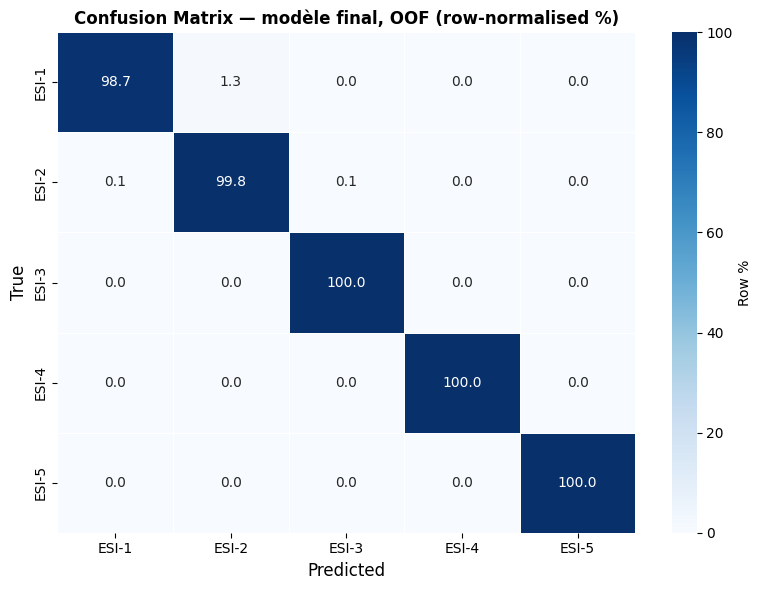

In [ ]:
cm = confusion_matrix(y_train, oof_labels)
cm_pct = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100

fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(cm_pct, annot=True, fmt='.1f', cmap='Blues', xticklabels=TARGET_NAMES, yticklabels=TARGET_NAMES,
            linewidths=0.5, ax=ax, cbar_kws={'label': 'Row %'})
ax.set_xlabel('Predicted', fontsize=12); ax.set_ylabel('True', fontsize=12)
ax.set_title('Confusion Matrix — modèle final, OOF (row-normalised %)', fontsize=12, fontweight='bold')
plt.tight_layout(); plt.show()

In [ ]:
# Tableau récapitulatif de toutes les expériences de ce notebook
rows = []
for _, r in structured_df.iterrows():
    rows.append({'expérience': r['label'], 'QWK': r['qwk']})
for r in text_results:
    rows.append({'expérience': 'NLP | ' + r['label'], 'QWK': r['qwk']})
for r in abl.values():
    rows.append({'expérience': 'Ablation | ' + r['label'], 'QWK': r['qwk']})
for r in strategy_results.values():
    rows.append({'expérience': r['label'], 'QWK': r['qwk']})
rows.append({'expérience': final_res['label'], 'QWK': final_res['qwk']})
summary_all = pd.DataFrame(rows)
print(summary_all.round(4).to_string(index=False))

                                  expérience    QWK
                        Structured | XGBoost 0.9309
                       Structured | LightGBM 0.9299
                       Structured | CatBoost 0.9291
                   Structured | RandomForest 0.9268
             Structured | LogisticRegression 0.9158
                           NLP | TF-IDF Only 0.8253
                           NLP | MiniLM Only 0.9991
                  NLP | BioClinicalBERT Only 0.9992
       Ablation | Baseline : struct + TF-IDF 0.9950
              Ablation | Base : struct + bcb 0.9996
Ablation | + complétude du bilan (manquance) 0.9997
            Ablation | + temporel / crowding 0.9996
         Ablation | + comorbidités enrichies 0.9997
                        Stratégie : balanced 0.9996
                      Stratégie : oversample 0.9995
                           Stratégie : focal 0.9993
                     MODÈLE FINAL (balanced) 0.9995


### 8.1 Analyse d'erreurs et calibration

On regarde **où** le modèle se trompe (erreurs à ±1 niveau vs grosses erreurs, sous-triage vs sur-triage) et si ses probabilités sont **fiables** (diagramme de fiabilité, ECE, Brier). Convention : erreur signée = prédit − vrai ; **positif = sous-triage** (patient classé moins urgent qu'il ne l'est).

Erreurs : 74 / 80,000 (0.09%)
  à ±1 niveau : 97.3% | à ≥ 2 niveaux : 2.7%
  sous-triage (prédit moins urgent) : 62 | sur-triage : 12

classe     n  erreur_%  sous-triage_%  sur-triage_%
 ESI-1  3222      1.27           1.27          0.00
 ESI-2 13439      0.24           0.16          0.08
 ESI-3 28921      0.00           0.00          0.00
 ESI-4 23020      0.00           0.00          0.00
 ESI-5 11398      0.00           0.00          0.00

Score de Brier multiclasse (OOF) : 0.0015
ECE ESI-1 : 0.0003
ECE ESI-2 : 0.0002


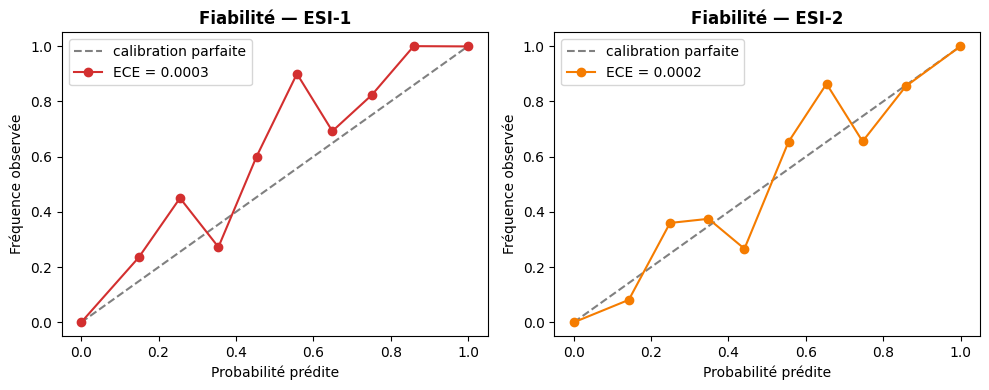

Rappel : class_weight='balanced' sur-estime les probabilités des classes rares -> recalibrer avant tout usage comme score de risque.


In [ ]:
pred = oof_labels
err = pred - y_train
n_err = int((err != 0).sum())
print(f'Erreurs : {n_err:,} / {len(err):,} ({n_err / len(err) * 100:.2f}%)')
if n_err:
    print(f'  à ±1 niveau : {(np.abs(err) == 1).sum() / n_err * 100:.1f}% | à ≥ 2 niveaux : {(np.abs(err) >= 2).sum() / n_err * 100:.1f}%')
    print(f'  sous-triage (prédit moins urgent) : {(err > 0).sum():,} | sur-triage : {(err < 0).sum():,}')

err_tab = pd.DataFrame({
    'classe': TARGET_NAMES,
    'n': np.bincount(y_train, minlength=5),
    'erreur_%': [(pred[y_train == k] != k).mean() * 100 for k in range(5)],
    'sous-triage_%': [(err[y_train == k] > 0).mean() * 100 for k in range(5)],
    'sur-triage_%': [(err[y_train == k] < 0).mean() * 100 for k in range(5)],
}).round(2)
print(); print(err_tab.to_string(index=False))


def ece_ovr(p, y_bin, n_bins=10):
    '''Expected Calibration Error un-contre-tous + points du diagramme de fiabilité.'''
    edges = np.linspace(0, 1, n_bins + 1)
    idx = np.clip(np.digitize(p, edges) - 1, 0, n_bins - 1)
    ece, pts = 0.0, []
    for b in range(n_bins):
        m = idx == b
        if m.any():
            ece += m.mean() * abs(p[m].mean() - y_bin[m].mean())
            pts.append((p[m].mean(), y_bin[m].mean()))
    return ece, np.array(pts)


brier = np.mean(np.sum((oof_prob - np.eye(5)[y_train]) ** 2, axis=1))
print(f'\nScore de Brier multiclasse (OOF) : {brier:.4f}')
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, k in zip(axes, [0, 1]):
    ece_k, pts = ece_ovr(oof_prob[:, k], (y_train == k).astype(int))
    ax.plot([0, 1], [0, 1], '--', color='gray', label='calibration parfaite')
    if len(pts):
        ax.plot(pts[:, 0], pts[:, 1], 'o-', color=ESI_COLORS[k], label=f'ECE = {ece_k:.4f}')
    ax.set_title(f'Fiabilité — {TARGET_NAMES[k]}', fontweight='bold')
    ax.set_xlabel('Probabilité prédite'); ax.set_ylabel('Fréquence observée'); ax.legend()
    print(f'ECE {TARGET_NAMES[k]} : {ece_k:.4f}')
plt.tight_layout(); plt.show()
print('Rappel : class_weight=\'balanced\' sur-estime les probabilités des classes rares -> recalibrer avant tout usage comme score de risque.')

### 8.2 Audit d'équité et de variabilité du triage

Trois questions distinctes :
1. **Le modèle performe-t-il de façon homogène** selon sexe, langue, assurance, site, mode d'arrivée, poste, tranche d'âge ? (QWK, rappel ESI-1, sous-triage critique par sous-groupe)
2. **Les étiquettes humaines contiennent-elles un biais** une fois la clinique prise en compte ? Régression de l'ESI sur NEWS2, GCS, âge et état mental, puis test de l'effet de chaque variable sociodémographique (coefficient en niveaux d'ESI, IC 95 %, test F emboîté).
3. **Les infirmiers diffèrent-ils systématiquement** ? Écart moyen entre l'ESI attribué et l'ESI attendu par le modèle sans texte, comparé à un test de permutation.

In [ ]:
if not RUN_FAIRNESS:
    print('RUN_FAIRNESS = False : audit d\'équité sauté.')
else:
    import statsmodels.formula.api as smf

    FAIR_COLS = [c for c in ['sex', 'language', 'insurance_type', 'arrival_mode', 'shift', 'site_id', 'age_group']
                 if c in train.columns]
    s_true, s_pred = y_train, oof_labels

    # ── (1) Performance du modèle par sous-groupe ────────────────────────
    rows = []
    for col in FAIR_COLS:
        vals = train[col].astype(str).values
        for v in sorted(np.unique(vals)):
            m = vals == v
            if m.sum() < 200:
                continue
            yt, yp = s_true[m], s_pred[m]
            crit = np.isin(yt, [0, 1])
            rows.append({'variable': col, 'valeur': v, 'n': int(m.sum()),
                         'QWK': cohen_kappa_score(yt, yp, weights='quadratic'),
                         'rappel_ESI1': ((yp == 0) & (yt == 0)).sum() / max((yt == 0).sum(), 1),
                         'sous-triage_critique_%': (crit & np.isin(yp, [3, 4])).sum() / max(crit.sum(), 1) * 100,
                         'erreur_signée_moy': (yp - yt).mean()})
    sub_df = pd.DataFrame(rows)
    print('(1) Performance par sous-groupe (modèle final, OOF) — écart max-min par variable :')
    gap = sub_df.groupby('variable').agg(QWK_min=('QWK', 'min'), QWK_max=('QWK', 'max'),
                                         rappel_ESI1_min=('rappel_ESI1', 'min'), rappel_ESI1_max=('rappel_ESI1', 'max'),
                                         sous_triage_max=('sous-triage_critique_%', 'max'))
    gap['écart_QWK'] = gap['QWK_max'] - gap['QWK_min']
    gap['écart_rappel_ESI1'] = gap['rappel_ESI1_max'] - gap['rappel_ESI1_min']
    FAIR_GAP = gap[['écart_QWK', 'écart_rappel_ESI1', 'sous_triage_max']].round(4)
    display(FAIR_GAP)
    print('Détail par sous-groupe :')
    display(sub_df.round(4))

    # ── (2) Biais d'étiquetage, ajusté sur la clinique ───────────────────
    base_terms = [t for t in ['news2_score', 'gcs_total', 'age', 'C(mental_status_triage)']
                  if t.replace('C(', '').replace(')', '') in train.columns]
    d = train.copy()
    d['y_esi'] = d['triage_acuity']
    f_base = 'y_esi ~ ' + ' + '.join(base_terms)
    fit_base = smf.ols(f_base, data=d).fit()
    print(f'\n(2) Biais d\'étiquetage ajusté sur la clinique ({f_base})')
    print('    coefficient = écart moyen d\'ESI (en niveaux) par rapport à la modalité de référence ; + = classé moins urgent')
    coef_rows, ftests = [], []
    for col in FAIR_COLS:
        fit_full = smf.ols(f_base + f' + C({col})', data=d).fit()
        f_val, p_val, _ = fit_full.compare_f_test(fit_base)
        ftests.append({'variable': col, 'F': f_val, 'p_F': p_val})
        rob = smf.ols(f_base + f' + C({col})', data=d).fit(cov_type='HC3')
        ci = rob.conf_int()
        for name in rob.params.index:
            if name.startswith(f'C({col})'):
                coef_rows.append({'variable': col, 'modalité': name.split('[T.')[-1].rstrip(']'),
                                  'coef_ESI': rob.params[name], 'IC95_bas': ci.loc[name, 0], 'IC95_haut': ci.loc[name, 1],
                                  'p': rob.pvalues[name]})
    ftest_df = pd.DataFrame(ftests).sort_values('p_F')
    ftest_df['signif_Bonferroni'] = ftest_df['p_F'] < 0.05 / max(len(ftest_df), 1)
    print('\n    Test F emboîté (la variable améliore-t-elle le modèle clinique ?) :')
    display(ftest_df.round(6))
    coef_df = pd.DataFrame(coef_rows)
    if len(coef_df):
        coef_df['|coef| >= 0.05 et p < 0.001'] = (coef_df['coef_ESI'].abs() >= 0.05) & (coef_df['p'] < 0.001)
        print('    Coefficients les plus forts :')
        display(coef_df.reindex(coef_df['coef_ESI'].abs().sort_values(ascending=False).index).head(10).round(4))
    LABEL_BIAS_FLAGGED = int(coef_df['|coef| >= 0.05 et p < 0.001'].sum()) if len(coef_df) else 0

    # ── (3) Variabilité inter-infirmiers (modèle sans texte) ─────────────
    if 'triage_nurse_id' in train.columns:
        exp_esi = notext_res['oof_prob'] @ np.arange(1, 6)               # ESI attendu (1-5) selon la clinique seule
        resid = train['triage_acuity'].values - exp_esi
        nurse = train['triage_nurse_id'].values
        stats = pd.Series(resid).groupby(nurse).agg(['mean', 'count'])
        stats = stats[stats['count'] >= 30]
        obs_sd = stats['mean'].std()
        rng_n, null = np.random.RandomState(SEED), []
        for _ in range(200):
            null.append(pd.Series(rng_n.permutation(resid)).groupby(nurse).mean().loc[stats.index].std())
        p_perm = (np.sum(np.array(null) >= obs_sd) + 1) / (len(null) + 1)
        print(f'\n(3) Variabilité inter-infirmiers ({len(stats)} infirmiers, ≥ 30 patients) :')
        print(f'    écart-type observé des écarts moyens = {obs_sd:.4f} | sous H0 (permutation) = {np.mean(null):.4f} | p ≈ {p_perm:.3f}')
        print('    Infirmiers les plus « sous-triants » (ESI attribué > attendu) :', stats['mean'].nlargest(3).round(3).to_dict())
        print('    Infirmiers les plus « sur-triants » (ESI attribué < attendu) :', stats['mean'].nsmallest(3).round(3).to_dict())
        NURSE_P = float(p_perm)
    else:
        NURSE_P = None

(1) Performance par sous-groupe (modèle final, OOF) — écart max-min par variable :


,écart_QWK,écart_rappel_ESI1,sous_triage_max
variable,,,
age_group,0.0004,0.0178,0.0409
arrival_mode,0.0004,0.0154,0.0215
insurance_type,0.0004,0.0152,0.0199
language,0.0009,0.0254,0.1493
sex,0.0003,0.0139,0.0255
shift,0.0003,0.0077,0.0238
site_id,0.0005,0.0179,0.0307


Détail par sous-groupe :


,variable,valeur,n,QWK,rappel_ESI1,sous-triage_critique_%,erreur_signée_moy
0,sex,F,40339,0.9996,0.9895,0.0000,0.0005
1,sex,M,37735,0.9995,0.9855,0.0255,0.0008
2,sex,Other,1926,0.9993,0.9756,0.0000,0.0016
3,language,Arabic,3944,0.9994,0.9939,0.1193,0.0008
4,language,English,8024,0.9997,0.9942,0.0000,0.0001
5,language,Estonian,4858,0.9990,0.9703,0.0000,0.0010
6,language,Finnish,44134,0.9995,0.9848,0.0000,0.0008
7,language,Other,3968,0.9999,0.9939,0.0000,0.0003
8,language,Russian,5587,0.9998,0.9909,0.0000,0.0004
9,language,Somali,3170,0.9989,0.9915,0.1493,0.0009



(2) Biais d'étiquetage ajusté sur la clinique (y_esi ~ news2_score + gcs_total + age + C(mental_status_triage))
    coefficient = écart moyen d'ESI (en niveaux) par rapport à la modalité de référence ; + = classé moins urgent

    Test F emboîté (la variable améliore-t-elle le modèle clinique ?) :


,variable,F,p_F,signif_Bonferroni
2,insurance_type,1.944488,0.100070,False
6,age_group,1.133180,0.334034,False
1,language,1.103370,0.357610,False
3,arrival_mode,0.619505,0.684954,False
0,sex,0.283662,0.753022,False
5,site_id,0.385581,0.819118,False
4,shift,0.285596,0.835841,False


    Coefficients les plus forts :


,variable,modalité,coef_ESI,IC95_bas,IC95_haut,p,|coef| >= 0.05 et p < 0.001
12,insurance_type,unknown,0.0335,0.0027,0.0644,0.0333,False
26,age_group,pediatric,-0.0270,-0.0688,0.0148,0.2053,False
10,insurance_type,private,0.0268,0.0052,0.0484,0.0152,False
11,insurance_type,public,0.0267,0.0060,0.0474,0.0115,False
27,age_group,young_adult,-0.0254,-0.0553,0.0045,0.0963,False
5,language,Other,-0.0240,-0.0494,0.0014,0.0644,False
14,arrival_mode,helicopter,-0.0200,-0.0443,0.0044,0.1080,False
9,insurance_type,none,0.0193,-0.0053,0.0438,0.1237,False
8,language,Swedish,-0.0181,-0.0412,0.0049,0.1228,False
7,language,Somali,-0.0160,-0.0426,0.0107,0.2408,False



(3) Variabilité inter-infirmiers (50 infirmiers, ≥ 30 patients) :
    écart-type observé des écarts moyens = 0.0078 | sous H0 (permutation) = 0.0082 | p ≈ 0.682
    Infirmiers les plus « sous-triants » (ESI attribué > attendu) : {'NURSE-0048': 0.0, 'NURSE-0047': -0.003, 'NURSE-0040': -0.005}
    Infirmiers les plus « sur-triants » (ESI attribué < attendu) : {'NURSE-0011': -0.04, 'NURSE-0003': -0.035, 'NURSE-0041': -0.029}


## 9. Feature Importance et SHAP (préfigure l'Étape 6 du pipeline)

L'importance est calculée en **gain** moyen sur les 5 plis (le baseline annonçait du gain mais `feature_importances_` renvoie le nombre de splits par défaut).

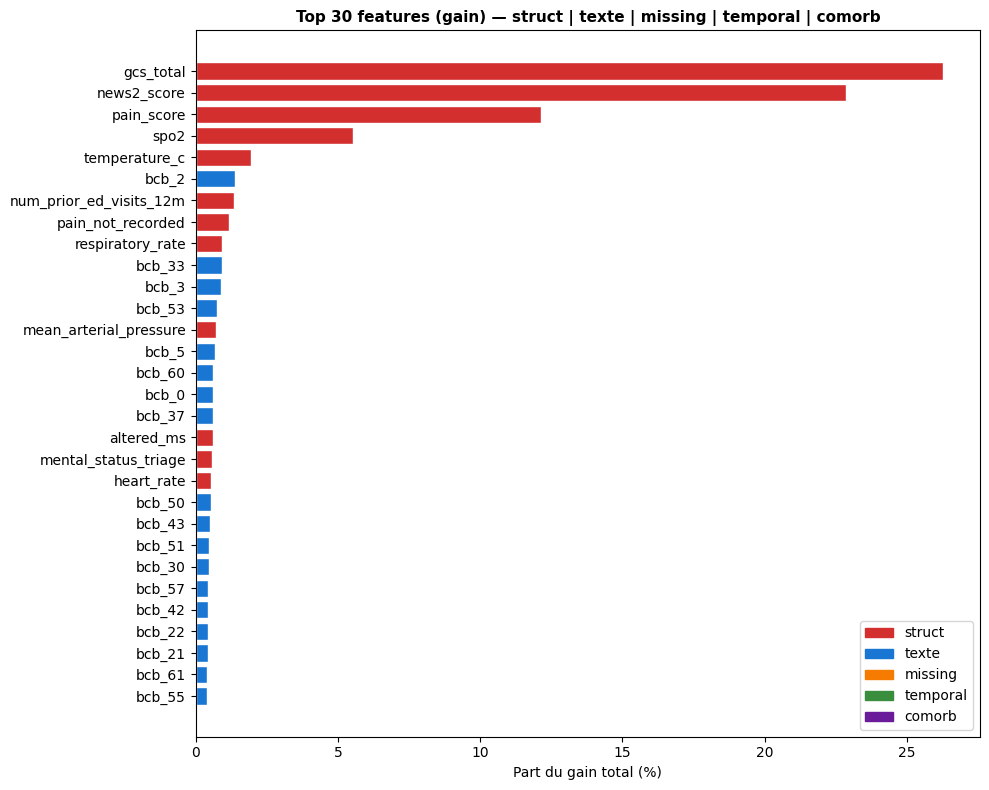

Part du gain par groupe de features :
groupe
struct    76.46
texte     23.54


In [ ]:
def _booster(m):
    return m.booster_ if hasattr(m, 'booster_') else m

COL2GROUP = {c: g for g, cols in GROUPS.items() for c in cols}
COL2GROUP.update({c: 'texte' for c in TEXT_BLOCKS[FINAL_TEXT_NAME].columns})

gain = np.mean([_booster(m).feature_importance(importance_type='gain') for m in final_res['models']], axis=0)
feat_imp = pd.DataFrame({'feature': X_sel_tr.columns, 'gain': gain})
feat_imp['share_%'] = feat_imp['gain'] / feat_imp['gain'].sum() * 100
feat_imp['groupe'] = feat_imp['feature'].map(COL2GROUP).fillna('struct')
feat_imp = feat_imp.sort_values('gain', ascending=False).reset_index(drop=True)

PALETTE = {'struct': '#d32f2f', 'texte': '#1976d2', 'missing': '#f57c00', 'temporal': '#388e3c', 'comorb': '#6a1b9a'}
top30 = feat_imp.head(30).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(top30['feature'], top30['share_%'], color=[PALETTE.get(g, 'gray') for g in top30['groupe']], edgecolor='white')
ax.set_xlabel('Part du gain total (%)')
ax.set_title('Top 30 features (gain) — ' + ' | '.join(f'{g}' for g in PALETTE), fontsize=11, fontweight='bold')
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in PALETTE.values()]
ax.legend(handles, PALETTE.keys(), loc='lower right')
plt.tight_layout(); plt.show()

print('Part du gain par groupe de features :')
print(feat_imp.groupby('groupe')['share_%'].sum().sort_values(ascending=False).round(2).to_string())

SHAP Summary Plot — ESI-1 (classe la plus critique)


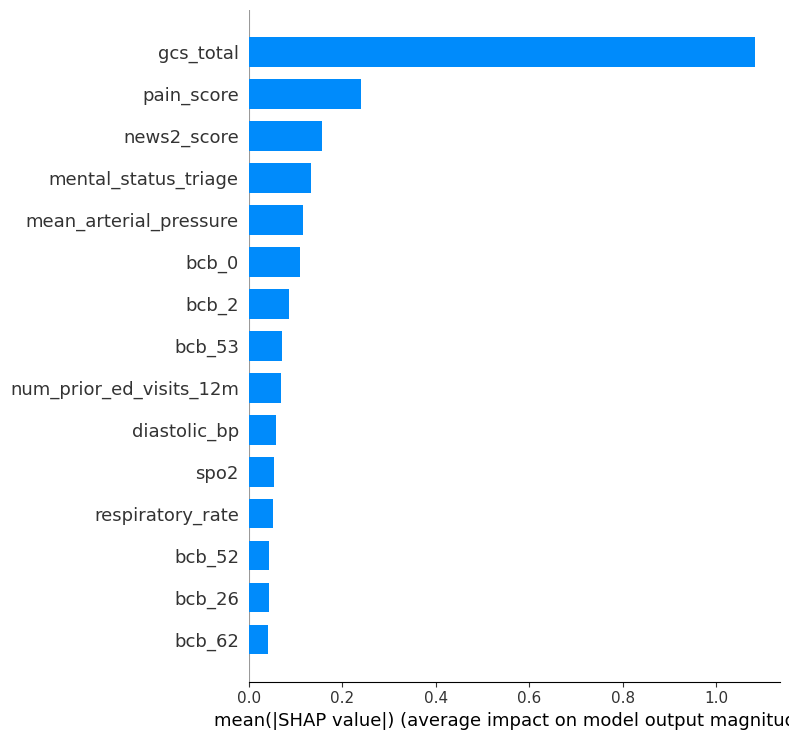

In [ ]:
# SHAP sur ESI-1 (classe la plus critique), modèle du premier pli
booster = _booster(final_res['models'][0])
X_sample = X_sel_tr.sample(n=min(SHAP_SAMPLE, len(X_sel_tr)), random_state=SEED)

explainer = shap.TreeExplainer(booster)
shap_values = explainer.shap_values(X_sample, check_additivity=False)
sv_esi1 = shap_values[0] if isinstance(shap_values, list) else shap_values[:, :, 0]   # compatible anciennes/nouvelles versions de shap

print('SHAP Summary Plot — ESI-1 (classe la plus critique)')
shap.summary_plot(sv_esi1, X_sample, max_display=15, plot_type='bar', show=True)

## 10. Sécurité clinique — sous-triage critique et garde-fou

**Risque identifié** : si un soignant mesure moins de signes vitaux chez un patient jugé peu urgent, la valeur manquante est corrélée à une acuité faible dans les étiquettes (EDA A4). Un modèle peut en faire un raccourci (« bilan incomplet ⇒ ESI-4/5 ») et **renforcer** un éventuel sous-triage initial. Deux parades :

1. **Métrique de sécurité** : taux de *sous-triage critique* (vrais ESI-1/2 prédits ESI-4/5), **stratifié par complétude du bilan**.
2. **Garde-fou post-modèle** : si un signe vital **réellement mesuré** est anormal (SpO₂ < 92, FC > 120, GCS < 14) **ou** si la plainte contient un mot de haute sévérité (*severe*, *shock*, *acute*), toute prédiction ESI-4/5 est remontée à ESI-3 minimum, indépendamment du score du modèle.

In [ ]:
def critical_undertriage_report(y_true, y_pred, missing_count, label=''):
    """Taux de sous-triage critique (vrais ESI-1/2 prédits ESI-4/5), par nombre de signes vitaux manquants."""
    y_true, y_pred, miss = np.asarray(y_true), np.asarray(y_pred), np.asarray(missing_count)
    bins = np.where(miss == 0, '0 manquant', np.where(miss == 1, '1 manquant', '2+ manquants'))
    rows = []
    for b in ['0 manquant', '1 manquant', '2+ manquants']:
        mask = bins == b
        crit = mask & np.isin(y_true, [0, 1])
        missed = crit & np.isin(y_pred, [3, 4])
        rows.append({'complétude du bilan': b, 'patients': int(mask.sum()), 'vrais ESI-1/2': int(crit.sum()),
                     'sous-triés (ESI-4/5)': int(missed.sum()),
                     'taux sous-triage critique %': round(missed.sum() / crit.sum() * 100, 2) if crit.sum() else np.nan})
    crit_all = np.isin(y_true, [0, 1]); missed_all = crit_all & np.isin(y_pred, [3, 4])
    rows.append({'complétude du bilan': 'TOTAL', 'patients': len(y_true), 'vrais ESI-1/2': int(crit_all.sum()),
                 'sous-triés (ESI-4/5)': int(missed_all.sum()),
                 'taux sous-triage critique %': round(missed_all.sum() / max(crit_all.sum(), 1) * 100, 2)})
    out = pd.DataFrame(rows)
    out.insert(0, 'prédictions', label)
    return out


# ── Garde-fou ────────────────────────────────────────────────────────────
OVERRIDE_RULES = {'spo2': ('<', 92), 'heart_rate': ('>', 120), 'gcs_total': ('<', 14)}   # ajoutez ex. 'systolic_bp': ('<', 90)
SEVERITY_REGEX = r'\b(?:severe|shock|acute)\b'
ESI3 = 2                                  # ESI-3, 0-indexé


def override_triggers(raw_vitals, texts):
    """Retourne (déclencheur vitaux, déclencheur texte). Les valeurs manquantes ne déclenchent jamais le garde-fou."""
    vit = np.zeros(len(raw_vitals), dtype=bool)
    for col, (op, thr) in OVERRIDE_RULES.items():
        if col in raw_vitals.columns:
            v = raw_vitals[col].values
            vit |= np.where(np.isnan(v), False, (v < thr) if op == '<' else (v > thr))
    txt = pd.Series(texts).str.contains(SEVERITY_REGEX, case=False, regex=True).values
    return vit, txt


def apply_safety_override(pred, raw_vitals, texts):
    vit, txt = override_triggers(raw_vitals, texts)
    mask = (vit | txt) & np.isin(pred, [3, 4])
    safe = pred.copy()
    safe[mask] = ESI3
    return safe, mask, vit, txt


rv_tr = RAW_VITALS[IS_TRAIN].reset_index(drop=True)
txt_tr = TEXT_ALL[IS_TRAIN]
miss_tr = F.loc[IS_TRAIN, 'vitals_missing_count'].values

oof_safe, ov_mask, ov_vit, ov_txt = apply_safety_override(oof_labels, rv_tr, txt_tr)

print(f'Garde-fou déclenché sur {ov_mask.sum():,} patients ({ov_mask.mean() * 100:.2f}% du train)')
for name, trig in [('vitaux anormaux', ov_vit), ('mot de sévérité', ov_txt)]:
    sel = trig & np.isin(oof_labels, [3, 4])
    if sel.sum():
        just = np.isin(y_train[sel], [0, 1, 2]).mean() * 100
        print(f'  déclencheur {name:16s}: {sel.sum():5d} remontées ; vrai ESI ≤ 3 dans {just:.1f}% des cas (justifiées)')

qwk_before = cohen_kappa_score(y_train, oof_labels, weights='quadratic')
qwk_after = cohen_kappa_score(y_train, oof_safe, weights='quadratic')
print(f'\nQWK avant garde-fou : {qwk_before:.4f} | après : {qwk_after:.4f} (Δ = {qwk_after - qwk_before:+.4f})')

report = pd.concat([critical_undertriage_report(y_train, oof_labels, miss_tr, 'modèle seul'),
                    critical_undertriage_report(y_train, oof_safe, miss_tr, 'modèle + garde-fou')], ignore_index=True)
report

Garde-fou déclenché sur 445 patients (0.56% du train)
  déclencheur vitaux anormaux :    99 remontées ; vrai ESI ≤ 3 dans 0.0% des cas (justifiées)
  déclencheur mot de sévérité :   347 remontées ; vrai ESI ≤ 3 dans 0.0% des cas (justifiées)

QWK avant garde-fou : 0.9995 | après : 0.9969 (Δ = -0.0026)


,prédictions,complétude du bilan,patients,vrais ESI-1/2,sous-triés (ESI-4/5),taux sous-triage critique %
0,modèle seul,0 manquant,72669,16661,2,0.01
1,modèle seul,1 manquant,3143,0,0,NaN
2,modèle seul,2+ manquants,4188,0,0,NaN
3,modèle seul,TOTAL,80000,16661,2,0.01
4,modèle + garde-fou,0 manquant,72669,16661,2,0.01
5,modèle + garde-fou,1 manquant,3143,0,0,NaN
6,modèle + garde-fou,2+ manquants,4188,0,0,NaN
7,modèle + garde-fou,TOTAL,80000,16661,2,0.01


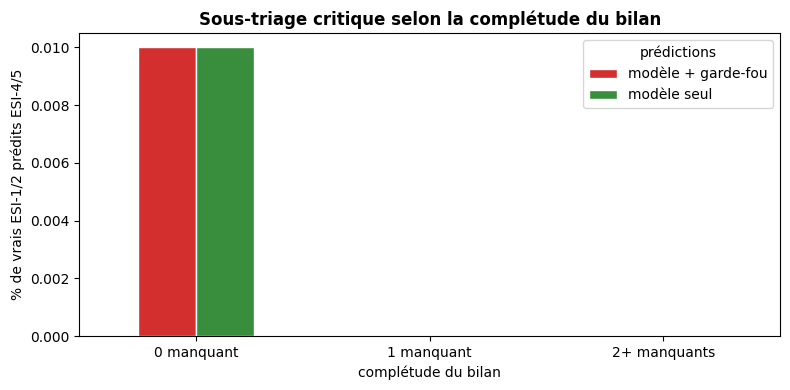

APPLY_OVERRIDE = True  (règle : perte de QWK ≤ 0.005)


In [ ]:
# Visualisation : sous-triage critique selon la complétude du bilan, avant / après garde-fou
rep = report[report['complétude du bilan'] != 'TOTAL']
piv = rep.pivot(index='complétude du bilan', columns='prédictions', values='taux sous-triage critique %')
piv = piv.reindex(['0 manquant', '1 manquant', '2+ manquants'])
fig, ax = plt.subplots(figsize=(8, 4))
piv.plot(kind='bar', ax=ax, color=['#d32f2f', '#388e3c'], edgecolor='white')
ax.set_ylabel('% de vrais ESI-1/2 prédits ESI-4/5')
ax.set_title('Sous-triage critique selon la complétude du bilan', fontsize=12, fontweight='bold')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

# Décision : le garde-fou est appliqué à la soumission seulement s'il ne dégrade pas sensiblement le QWK.
# Le QWK est la métrique de la compétition ; la sécurité clinique est un objectif distinct du projet : forcez True/False si besoin.
APPLY_OVERRIDE = bool(qwk_after >= qwk_before - 0.005)
print(f'APPLY_OVERRIDE = {APPLY_OVERRIDE}  (règle : perte de QWK ≤ 0.005)')

## 11. Generate Submission

In [ ]:
test_pred = test_prob.argmax(axis=1)                       # 0-indexé

if APPLY_OVERRIDE:
    rv_te = RAW_VITALS[~IS_TRAIN].reset_index(drop=True)
    test_pred, te_mask, _, _ = apply_safety_override(test_pred, rv_te, TEXT_ALL[~IS_TRAIN])
    print(f'Garde-fou appliqué au test : {te_mask.sum():,} remontées vers ESI-3')

id_col, target_col = sample_sub.columns[0], sample_sub.columns[1]
submission = pd.DataFrame({id_col: test['patient_id'].values, target_col: test_pred + 1})   # retour à l'échelle ESI 1-5

# Contrôles de conformité avec sample_submission.csv
assert set(submission[id_col]) == set(sample_sub[id_col]), 'Les patient_id ne correspondent pas au fichier modèle'
assert submission[target_col].between(1, 5).all()
submission = sample_sub[[id_col]].merge(submission, on=id_col, how='left')              # même ordre que sample_submission
assert len(submission) == len(sample_sub) and submission[target_col].notna().all()

print('Distribution des acuités prédites (test) :')
print(submission[target_col].value_counts().sort_index())

submission.to_csv('submission.csv', index=False)
submission.to_csv(os.path.join(ARTIFACT_DIR, 'submission.csv'), index=False)
print('\nsubmission.csv enregistré (répertoire courant et ARTIFACT_DIR).')
submission.head()

Garde-fou appliqué au test : 112 remontées vers ESI-3
Distribution des acuités prédites (test) :
triage_acuity
1     766
2    3402
3    7361
4    5712
5    2759
Name: count, dtype: int64

submission.csv enregistré (répertoire courant et ARTIFACT_DIR).


,patient_id,triage_acuity
0,TG-FZUFCRZS3,2
1,TG-SSCOXTYI1,3
2,TG-JY74ZR35D,2
3,TG-JDKD5G62X,4
4,TG-J1BSAAXR0,4


In [ ]:
# Soumission alternative « sans texte » (+ décodage ordinal si validé en 7.2) : fichier séparé, à choisir en connaissance de cause
if not USE_TEXT_IN_FINAL:
    print('USE_TEXT_IN_FINAL = False : la soumission principale est déjà sans texte.')
else:
    e_te = notext_res['test_prob'] @ np.arange(5)
    alt_pred = np.digitize(e_te, TH_FINAL) if USE_ORDINAL_DECODING else notext_res['test_prob'].argmax(axis=1)
    if APPLY_OVERRIDE:
        alt_pred, alt_mask, _, _ = apply_safety_override(alt_pred, RAW_VITALS[~IS_TRAIN].reset_index(drop=True), TEXT_ALL[~IS_TRAIN])
        print(f'Garde-fou appliqué (soumission sans texte) : {alt_mask.sum():,} remontées vers ESI-3')
    sub_nt = pd.DataFrame({id_col: test['patient_id'].values, target_col: alt_pred + 1})
    sub_nt = sample_sub[[id_col]].merge(sub_nt, on=id_col, how='left')
    assert len(sub_nt) == len(sample_sub) and sub_nt[target_col].between(1, 5).all()
    sub_nt.to_csv('submission_notext.csv', index=False)
    sub_nt.to_csv(os.path.join(ARTIFACT_DIR, 'submission_notext.csv'), index=False)
    print('Distribution des acuités prédites (sans texte) :')
    print(sub_nt[target_col].value_counts().sort_index())
    print('\nsubmission_notext.csv enregistré (la soumission principale reste submission.csv).')

Garde-fou appliqué (soumission sans texte) : 186 remontées vers ESI-3
Distribution des acuités prédites (sans texte) :
triage_acuity
1     758
2    3383
3    7299
4    5491
5    3069
Name: count, dtype: int64

submission_notext.csv enregistré (la soumission principale reste submission.csv).


## 12. Sauvegarde des artefacts (point de départ de l'Étape 5 — optimisation PSO)

Tout est écrit dans `ARTIFACT_DIR` (sur Google Drive si vous êtes sous Colab), ce qui permet de reprendre le projet sans tout recalculer.

In [ ]:
joblib.dump(X_sel_tr, os.path.join(ARTIFACT_DIR, 'X_train_final.pkl'), compress=3)
joblib.dump(X_sel_te, os.path.join(ARTIFACT_DIR, 'X_test_final.pkl'), compress=3)
joblib.dump(y_train,  os.path.join(ARTIFACT_DIR, 'y_train.pkl'))
joblib.dump(tfidf_vec, os.path.join(ARTIFACT_DIR, 'tfidf_vectorizer.pkl'))
joblib.dump(comorb_pca, os.path.join(ARTIFACT_DIR, 'comorbidity_pca.pkl'))
joblib.dump({'oof_prob': oof_prob, 'test_prob': test_prob}, os.path.join(ARTIFACT_DIR, 'final_probabilities.pkl'), compress=3)

config = {'seed': SEED, 'n_folds': N_FOLDS, 'use_groups': USE_GROUPS, 'final_text': FINAL_TEXT_NAME,
          'final_strategy': FINAL_STRATEGY, 'lgb_final_params': LGB_FINAL, 'apply_override': APPLY_OVERRIDE,
          'qwk_oof': float(final_res['qwk']), 'recall_esi1': float(final_res['recall_esi1']),
          'crit_miss_pct': float(final_res['crit_miss_pct']), 'quick_debug': QUICK_DEBUG,
          'n_features': int(X_sel_tr.shape[1]), 'use_text_in_final': USE_TEXT_IN_FINAL,
          'qwk_without_text': float(notext_res['qwk']),
          'qwk_grouped_cv': (float(grouped_res['qwk']) if grouped_res is not None else None),
          'qwk_text_lookup': float(qwk_lk), 'use_ordinal_decoding': bool(USE_ORDINAL_DECODING)}
with open(os.path.join(ARTIFACT_DIR, 'config_final.json'), 'w') as f:
    json.dump(config, f, indent=2)

print('Artefacts sauvegardés dans', ARTIFACT_DIR)
print(json.dumps({k: v for k, v in config.items() if k != 'lgb_final_params'}, indent=2))

Artefacts sauvegardés dans /content/drive/MyDrive/triagegeist/artifacts/
{
  "seed": 2025,
  "n_folds": 5,
  "use_groups": [
    "struct"
  ],
  "final_text": "bcb",
  "final_strategy": "balanced",
  "apply_override": true,
  "qwk_oof": 0.999537367077637,
  "recall_esi1": 0.9872749844816884,
  "crit_miss_pct": 0.012004081387671808,
  "quick_debug": false,
  "n_features": 143,
  "use_text_in_final": true,
  "qwk_without_text": 0.9313292987289503,
  "qwk_grouped_cv": 0.9947697015063863,
  "qwk_text_lookup": 0.9932392877267976,
  "use_ordinal_decoding": false
}


## 13. Résultats clés et conclusion

Le tableau ci-dessous est **généré automatiquement** à partir des variables calculées plus haut (aucun chiffre saisi à la main).

In [ ]:
from IPython.display import Markdown, display

def _fmt(x, d=4):
    return 'n/a' if x is None else f'{x:.{d}f}'

rows_md = ['| Modèle / test | QWK (OOF) | Rappel ESI-1 | Sous-triage critique % |', '|---|---|---|---|']
for r in [final_res, notext_res] + ([grouped_res] if grouped_res is not None else []):
    rows_md.append(f'| {r["label"]} | {_fmt(r["qwk"])} | {_fmt(r["recall_esi1"], 3)} | {_fmt(r["crit_miss_pct"], 2)} |')
rows_md.append(f'| Table de correspondance texte → acuité (sans modèle) | {_fmt(qwk_lk)} | – | – |')

fair_line = 'audit d\'équité non exécuté'
if 'FAIR_GAP' in globals():
    fair_line = (f'écart max de QWK entre sous-groupes = {FAIR_GAP["écart_QWK"].max():.4f} ; '
                 f'écart max de rappel ESI-1 = {FAIR_GAP["écart_rappel_ESI1"].max():.4f} ; '
                 f'{LABEL_BIAS_FLAGGED} coefficient(s) d\'étiquetage |≥ 0.05 ESI| significatifs ; '
                 f'p(permutation, variabilité inter-infirmiers) = {_fmt(NURSE_P, 3)}')

md_text = f'''
{chr(10).join(rows_md)}

- **Sécurité** : QWK avant / après garde-fou = {qwk_before:.4f} / {qwk_after:.4f} ; garde-fou appliqué à la soumission : **{APPLY_OVERRIDE}**.
- **Décodage ordinal (sans texte)** : gain hors-échantillon = {ord_gain:+.4f} -> utilisé : **{USE_ORDINAL_DECODING}**.
- **Équité** : {fair_line}.
- **Modèle soumis** : {"avec" if USE_TEXT_IN_FINAL else "sans"} texte ; fichiers `submission.csv`{" et `submission_notext.csv`" if USE_TEXT_IN_FINAL else ""}.

**Lecture honnête** : si le QWK avec texte est proche de 1 alors que la table de correspondance texte → acuité atteint presque le même niveau et que la CV groupée ou le modèle sans texte chutent, le gain vient d'un artefact de génération des plaintes, pas d'une meilleure compréhension clinique. La performance **sans texte** est alors la référence à retenir pour la discussion clinique.
'''
display(Markdown(md_text))


| Modèle / test | QWK (OOF) | Rappel ESI-1 | Sous-triage critique % |
|---|---|---|---|
| MODÈLE FINAL (balanced) | 0.9995 | 0.987 | 0.01 |
| SANS TEXTE (balanced) | 0.9313 | 0.939 | 0.00 |
| Avec texte (bcb), CV groupée par plainte | 0.9948 | 0.985 | 0.02 |
| Table de correspondance texte → acuité (sans modèle) | 0.9932 | – | – |

- **Sécurité** : QWK avant / après garde-fou = 0.9995 / 0.9969 ; garde-fou appliqué à la soumission : **True**.
- **Décodage ordinal (sans texte)** : gain hors-échantillon = +0.0005 -> utilisé : **False**.
- **Équité** : écart max de QWK entre sous-groupes = 0.0009 ; écart max de rappel ESI-1 = 0.0254 ; 0 coefficient(s) d'étiquetage |≥ 0.05 ESI| significatifs ; p(permutation, variabilité inter-infirmiers) = 0.682.
- **Modèle soumis** : avec texte ; fichiers `submission.csv` et `submission_notext.csv`.

**Lecture honnête** : si le QWK avec texte est proche de 1 alors que la table de correspondance texte → acuité atteint presque le même niveau et que la CV groupée ou le modèle sans texte chutent, le gain vient d'un artefact de génération des plaintes, pas d'une meilleure compréhension clinique. La performance **sans texte** est alors la référence à retenir pour la discussion clinique.



## 14. Limitations connues de cette version

1. **Données très probablement synthétiques** : le texte de la plainte reconstitue presque l'acuité (5.3), et les caractéristiques cliniques (âge sans lien avec l'acuité, absence d'effet du sexe/langue/assurance) ne ressemblent pas à un vrai service d'urgences. Le QWK ≈ 0.999 avec texte **ne se transfère pas** à la pratique ; le modèle **sans texte** (7.1) est la référence réaliste. Une validation externe (MIMIC-IV-ED) reste à faire.
2. **Poids cliniques des comorbidités** : approximations à valider avec un avis clinique ; l'ablation montre un apport négligeable.
3. **Focal loss** : implémentation expérimentale (facteur focal traité comme un poids constant dans le gradient).
4. **Oversampling** : duplication aléatoire ; SMOTENC serait l'alternative pour des données mixtes.
5. **Garde-fou** : seuils (SpO₂ < 92, FC > 120, GCS < 14) et mots-clés (*severe, shock, acute*) choisis a priori ; *acute* apparaît aussi en ESI-2/3 : vérifiez la part de remontées « justifiées » (section 10).
6. **Décodage ordinal** (7.2) : seuils ajustés sur l'OOF ; le gain est estimé en validation croisée à deux plis, mais reste à confirmer sur des données externes.
7. **Calibration** (8.1) : les probabilités issues de `class_weight='balanced'` sont sur-estimées pour les classes rares ; à recalibrer (isotonique / température) avant tout usage comme score de risque.
8. **Crowding** : proxy calculé à partir du volume du jeu de données, pas de la charge réelle du service.
9. **Équité** : l'audit (8.2) détecte des écarts statistiques, pas leur cause ; un biais présent dans les étiquettes (triage humain) serait reproduit par le modèle.
10. **Corrélation ≠ causalité** : la manquance des signes vitaux est un signal, pas une règle clinique.

### Reproductibilité
- Graine `2025` partout ; validation croisée stratifiée à 5 plis identique pour toutes les expériences.
- `QUICK_DEBUG = True` permet de vérifier tout le notebook en quelques minutes avant un run complet.
- Sur Kaggle, activez le GPU pour BioClinicalBERT ou désactivez `RUN_BCB` ; sans internet, les embeddings sont désactivés automatiquement (sauf cache présent).


In [ ]:
import platform, sklearn
print(f'Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}')
print(f'LightGBM {lgb.__version__} | XGBoost {xgb.__version__} | shap {shap.__version__}')

Python 3.13.18 | pandas 2.2.3 | numpy 2.4.6 | scikit-learn 1.6.1
LightGBM 4.6.0 | XGBoost 3.4.1 | shap 0.54.1


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
!find /content/drive/MyDrive -name "triagegeist_baseline_ameliore.ipynb"

/content/drive/MyDrive/Colab Notebooks/triagegeist_baseline_ameliore.ipynb


In [4]:
%cd /content

!rm -rf /content/Triagegeist

!git config --global user.name "nayrouz20"
!git config --global user.email "nayrouzweslati2002@gmail.com"

/content


In [5]:
import shutil

shutil.copy(
    '/content/drive/MyDrive/Colab Notebooks/triagegeist_baseline_ameliore.ipynb',
    '/content/triagegeist_baseline_ameliore.ipynb'
)

'/content/triagegeist_baseline_ameliore.ipynb'